# 04 Creep-event detection, size, extent and the slip budget

```
Author: Danielle Lindsay
Environment: opera_disp_feb13. Run time: a few minutes (bootstraps and per-crossing fits).
```

**What this notebook does.** It defines the creep-event dates. Every later notebook reads them from
`creep_events.csv`.

1. **Detection** on the stacked fault-parallel series of the Tule Pond section (the crossings within 2 km
   along the trace of the section centre). The rate and annual cycle are removed, a step statistic (the mean
   of the next 3 acquisitions minus the mean of the previous 3) is computed at every gap between
   acquisitions, and the gaps where it exceeds 3 robust standard deviations are flagged. The Oakland section
   (COZ1 creepmeter) is processed in the same way as a control.
2. **Size and timing** from one joint model per stack (secular rate, annual harmonic and one step per
   event), with each step epoch grid-searched over the acquisition epochs. The onset window runs from the
   last acquisition before the step (`onset_lo`) to the first acquisition after it (`onset_hi`), one
   acquisition interval of 6 or 12 d. The confidence intervals on the steps come from a moving-block
   bootstrap.
3. **Along strike**, the same joint model is fitted at every crossing with the step epochs held fixed. It
   gives the per-event slip profiles, the inter-event (secular) rate and the event-driven fraction of slip.
4. **Section lengths**: (a) the length of fault hosting the events, where the cumulative event slip exceeds
   a threshold set from the scatter on the flanks; (b) the width of the peak slip zone, where the
   event-driven fraction is at least 90 % of its peak (the 90 % band).
5. **Band stack**: the joint model fitted to the mean series of the crossings in the 90 % band, which gives
   the step amplitudes quoted for the five events.
6. **Slip budget**: the inter-event rate plus the event-driven rate (the five Tule Pond events only),
   compared with the alignment arrays (refit over the InSAR window, and their whole-record rates) and the
   creepmeters.
7. **Seismicity**: the number of earthquakes in the GrowClust relocated catalogue and in the two
   repeating-earthquake catalogues within 2 km of the trace, in the section hosting the events and in the
   90 % band, over the InSAR period. The repeat intervals are computed in notebook 13.

All series use the 30 to 150 m bin at coherence 0.7.

**Inputs**: `03_creep_timeseries/fp_ts.csv`, `02_velocity_decomposition/fp_velocity_map.h5`, the per-track
line-of-sight tables `03_creep_timeseries/creep_ts_LOS_<track>.csv` (acquisition dates only), the fault
trace, the alignment-array summary and survey files, the five creepmeter records, the GrowClust catalogue,
the two repeating-earthquake catalogues and the Johnson et al. (2022) creep-rate compilation.

**Outputs** (`outputs/04_event_detection/`): `creep_events.csv` (one row per event: the onset window
`onset_lo` to `onset_hi` in decimal years, its first calendar day `onset_day`, which also labels the COZ1
events in the registry, and the step size), `creepmeter_events_COZ1.csv` (the creepmeter's own detections;
`detect_yr` is the time of the detector's flag), `event_fraction_by_crossing.csv`, `section_lengths.csv`,
`fig1_inputs.npz` (the arrays Fig 1 is drawn from, section 14), `04_events_stats.txt`, registry rows `04_*`.

**Figures** (in the dated figure folder, .png and .pdf): `figS_event_detection_<params>_k3_win3`
(detection QC, supplement); `figS_creep_rate_along_fault_<params>` (trace azimuth, creep rate per crossing
and slip budget along the whole fault, supplement). Fig 1 (rotated map, Hovmöller diagram, per-event
profiles, creep rates, band stack) is drawn in notebook 14 from `fig1_inputs.npz`.

**What to check.** The printed event list (section 5): five Tule Pond events, and the Oakland control
events, which must include the two large COZ1 events of January 2019 and February 2022 (asserted) and are
compared with the creepmeter's own detections. COZ1 events are labelled by onset day, not year. Section 6
repeats the detection at 3.5 and 4 times the noise level and asserts the same five events, and asserts that
every onset window agrees with each track's real acquisitions. The event-driven fraction near each section
centre (section 8), the band-stack amplitudes (section 11) and the slip-budget blocks against the
alignment-array rates (section 12) are printed.

## 1. Imports

In [1]:
import os
import warnings

import insar_utils as utils
from TulePond_filepaths import (common_paths, segments, creepmeters, params, coh_timeseries, insar_dic_list,
                                max_interp_gap_days, profile_smooth_km, creepmeter_glitches, paper_band_frac,
                                coz1_large_events_yr, coz1_large_tol_days, rate_smooth_km,
                                paths_out, repo_dir)   # profile_smooth_km: the 0.2 km Gaussian of Fig 1C and 1D

import numpy as np                               # Matrix calculations
import pandas as pd                              # Tables
import h5py                                      # fault-parallel velocity map (notebook 02)
import matplotlib.pyplot as plt

## 2. Paths and parameters

The settings of the detector, the along-strike profiles and the slip budget. `SEGS` lists the two sections
analysed, Tule Pond and the Oakland control (COZ1). For each it gives a title, the segment key, the name of
its fraction column, a search window (centre and half-width, km from Point Pinole) and the creepmeter used
as a control. The search window only bounds where the along-fault peak of event slip is looked for: for
Tule Pond, the peak of the cumulative slip above the inter-event rate (section 9); for Oakland, the peak of
its event-driven fraction (section 10). The section extent and the bands are then measured from the data
within it. The Tule Pond half-width also sets the half-width of the along-strike window of section 9. The
detection stacks are centred on the section centres of `segments` (TulePond_filepaths).

In [2]:
notebook = "04_event_detection"
out_dir = os.path.join(common_paths["out_dir"], notebook)
fig_dir = common_paths["fig_dir"]
os.makedirs(out_dir, exist_ok=True)
os.makedirs(fig_dir, exist_ok=True)

# the detector
stack_half_km = 2.0     # half-width of the detection stack about the section centre, km along the trace
#                         (lat_to_km_map); narrower than the section, which includes fault that does not slip
win_n = 3               # acquisitions on each side of the gap in the step statistic
k_sigma = 3.0           # detection threshold in robust sigma of the statistic
merge_yr = 0.15         # flags closer than this (yr) are one event
step_search_yr = 0.10   # the step epoch is grid-searched over the acquisitions within this (yr) of the detection
nboot = 2000            # block bootstrap resamples for the amplitude CIs
block_years = 1.0       # bootstrap block length (years)
seed = 0                # bootstrap random seed

# along strike
min_epoch_frac = 0.5    # a crossing needs >50% finite epochs to be fitted
smooth_km = 0.4         # along-fault smoothing of the profiles (gap-preserving; sigma in km along the trace)
total_floor_mm = 1.0    # |total slip| below this: fraction undefined
band_main = paper_band_frac  # the peak slip zone: fraction >= this x its local peak (TulePond_filepaths, also read by 13)
band_fracs = (band_main,)
flank_km = ((52.0, 56.0), (64.0, 68.0))   # flanks for the creep-length threshold (Tule Pond, km from Point Pinole)
seis_max_dist_km = 2.0  # seismicity and repeaters within this of the trace
neg_floor_frac = 0.2    # hovmoller colour scale starts at -this x vmax so early-epoch noise is not clipped to white

# the slip budget and the alignment arrays
aa_min_surveys = 4      # an array is refit over the InSAR window only with this many surveys ...
aa_min_span_yr = 5.0    # ... spanning at least this many years
aa_max_dist_km = 2.0    # alignment arrays within this of the trace
km_lim = (-1.0, 70.0)   # x range of the supplement creep-rate figure (km from Point Pinole)
rate_band_half_km = 0.5  # Fig 1D shading: 5-95 % of the per-crossing rates within +/- this along the trace (11 crossings) ...
rate_band_min_n = 5      # ... drawn as shading only where at least this many crossings have a rate
strike_map = 144.0      # page rotation of the map panel (mean strike, notebook 02)
ref_patch_km = 5.0      # map display reference: CTM1-COZ1 patch, +/- this across the fault

# The two sections analysed: (title, segment key, fraction column, search centre km, search half-width km, creepmeter).
# The search window only bounds where the along-fault peak of event slip is looked for; the section extent and the
# 90 % band are then measured from the data within it.
SEGS = [("Tule Pond", "TULEPOND", "tulepond", 58.0, 10.0, ""),
        ("Oakland (control)", "COZ1", "coz1", 32.0, 15.0, "COZ1")]

fp_ts_file = os.path.join(paths_out["03_creep_timeseries"], "fp_ts.csv")
map_file = os.path.join(paths_out["02_velocity_decomposition"], "fp_velocity_map.h5")
# each track's real acquisition dates (the columns of the per-track LOS tables of 03), for the check of section 6
track_files = {}
for dic in insar_dic_list:
    track_files[dic["ORBIT_DIRECTION"]] = os.path.join(paths_out["03_creep_timeseries"], f"creep_ts_LOS_{dic['ORBIT_DIRECTION']}.csv")

REG = utils.Registry(notebook, common_paths, repo_dir)
creepmeter_files = []
for code, lat, lon, name in creepmeters:
    creepmeter_files.append(utils.creepmeter_file(common_paths["creepmeter_dir"], code))
REG.inputs(fp_ts_file, map_file, *track_files.values(), common_paths["fault_profiles"], common_paths["aa_summary"],
           common_paths["CRE_Taira"], common_paths["CRE_Wald"], common_paths["growclust_cat"],
           *creepmeter_files)

Registry for 04_event_detection: run ab27932e, git 28b62b0+


## 3. Load the fault-parallel time series, the along-fault axis and the trace

The fault-parallel series of notebook 03 has one row per 100 m crossing and one column per acquisition
(mm). Each crossing is placed at its distance $x$ along the trace from Point Pinole (km, positive to the
south). `load_stack` averages the rows within 2 km along the trace of a section centre that have finite
values at more than half of the epochs.

In [3]:
# the fault-parallel time series from 03: lat x decimal year, mm, rows south -> north
fp_ts = pd.read_csv(fp_ts_file, index_col=0)
fp_ts.columns = fp_ts.columns.astype(float)
fp_ts.index = fp_ts.index.astype(float)
fp_ts = fp_ts.sort_index()
lats = fp_ts.index.values
dates = fp_ts.columns.values.astype(float)
fp_matrix = fp_ts.values
t0, t1 = float(dates.min()), float(dates.max())
span = t1 - t0

# the along-fault axis: km from Point Pinole, increasing south
to_km = utils.lat_to_km_map(common_paths["fault_profiles"])
km = to_km(lats)
north_to_south = np.argsort(km)
km_sorted = km[north_to_south]
lats_sorted = lats[north_to_south]


def lat_of_km(km_value):
    """Latitude of the crossing at a distance along the trace.

    Parameters
    ----------
    km_value : float
        Distance from Point Pinole along the trace (km).

    Returns
    -------
    float
        Latitude (deg), linearly interpolated along the sorted axis.
    """
    return float(np.interp(km_value, km_sorted, lats_sorted))


x_fault = pd.read_csv(common_paths["fault_profiles"])
print(f"fp_ts: {len(lats)} crossings ({km.min():.1f} to {km.max():.1f} km from Point Pinole) x {len(dates)} epochs, "
      f"{t0:.3f} to {t1:.3f} ({span:.2f} yr); coherence {coh_timeseries}")


def load_stack(seg):
    """Mean fault-parallel series of the crossings near a section centre.

    Averages the rows of fp_ts within +/- stack_half_km along the trace of the section centre that have
    finite values at more than half of the epochs.

    Parameters
    ----------
    seg : dict
        Section entry of `segments` (TulePond_filepaths); "lat" is the section centre (deg).

    Returns
    -------
    dates : ndarray
        Epochs at which the mean is finite (decimal years).
    stack : ndarray
        Mean fault-parallel displacement at those epochs (mm).
    n_crossings : int
        Number of crossings averaged.
    """
    centre_km = float(to_km([seg["lat"]])[0])          # fp_ts is indexed by latitude; km is its along-trace position
    nearby = fp_ts[np.abs(km - centre_km) <= stack_half_km + 1e-6]
    nearby = nearby[nearby.notna().sum(axis=1) > 0.5 * fp_ts.shape[1]]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        stack = np.nanmean(nearby.values, axis=0)
    ok = np.isfinite(stack)
    return dates[ok], stack[ok], len(nearby)

fp_ts: 611 crossings (0.0 to 68.4 km from Point Pinole) x 439 epochs, 2016.672 to 2026.216 (9.54 yr); coherence 0.7


## 4. The step detector and the joint model

A creep event is modelled as a step in the series after removal of the rate and annual cycle. The residual
varies over periods of months (residual atmospheric delay), so the detector uses a short-window difference
rather than the residual level. It is one-sided: only forward steps are flagged, because the fault is
assumed not to slip backwards. The timing comes from the detector and the amplitude from the joint fit,
because a fit made locally around one event absorbs part of the step into its own trend. The same
functions are applied to both stacks, to the creepmeter and along strike.

**The joint model.** All terms are fitted together by least squares (`design`, `fit_joint`):

$$d(t_j) = a + b\,(t_j - \bar{t}) + c_1 \sin(2\pi t_j) + c_2 \cos(2\pi t_j) + \sum_{k=1}^{K} A_k\,H(t_j - \tau_k) + \epsilon_j,$$

where $d(t_j)$ is the fault-parallel displacement at acquisition $j$ (mm), $t_j$ its epoch (decimal
years), $\bar{t}$ the mean epoch (decimal years), $a$ a constant (mm), $b$ the secular (inter-event) rate
(mm/yr), $c_1$ and $c_2$ the amplitudes of the annual sine and cosine (mm), $A_k$ the step of event $k$
(mm), $\tau_k$ its step epoch (decimal years), $K$ the number of events, $\epsilon_j$ the misfit (mm), and
$H(x)$ the Heaviside function, 1 for $x > 0$ and 0 otherwise. The step therefore appears at the first
acquisition after $\tau_k$, and $\tau_k$ is the last acquisition before the event. The printed annual
amplitude is $\sqrt{c_1^2 + c_2^2}$ (mm). The residual sum of squares is

$$\mathrm{RSS} = \sum_{j=1}^{N} \left(d(t_j) - \hat{d}(t_j)\right)^2,$$

where $\hat{d}$ is the fitted model, $N$ the number of acquisitions and RSS is in mm$^2$. The printed RMS
is $\sqrt{\mathrm{RSS}/N}$ (mm). The model without steps ($K = 0$, `detrend_rate_annual`) is fitted first
and subtracted, which gives the residual $r_j$ (mm) that the detector uses.

**The step statistic.** At the gap between acquisitions $i-1$ and $i$ (`step_statistic`),

$$s_i = \frac{1}{n}\sum_{m=0}^{n-1} r_{i+m} \;-\; \frac{1}{n}\sum_{m=1}^{n} r_{i-m}, \qquad n + 1 \le i \le N - n,$$

placed at the gap midpoint $(t_{i-1} + t_i)/2$, where $s_i$ is in mm and $n = 3$ is the window, the number
of acquisitions on each side (`win_n`). Three acquisitions span 18 d at the 6 d repeat and 36 d at the
12 d repeat, so a step must persist beyond a single acquisition. The noise level of the statistic is its
robust standard deviation over the section's whole record (`utils.robust_sigma`) [citation needed],

$$\sigma_s = 1.4826\;\mathrm{median}_i \left|s_i - \mathrm{median}(s)\right|,$$

in mm, where the factor 1.4826 scales the median absolute deviation (MAD) to the standard deviation of a
normal distribution. A gap is flagged when (`detect`)

$$s_i > k\,\sigma_s,$$

with $k = 3$ (`k_sigma`). A flag closer than 0.15 yr (`merge_yr`) to the previous flag belongs to the same
event, and the larger statistic is kept. The detection time `detect_yr` is the gap where the statistic
peaks.

**Timing, then amplitude.** `grid_search` finds the step epoch of one event with the other events held
fixed. It tries as $\tau_k$ every acquisition epoch within 0.10 yr (`step_search_yr`) of the current
estimate, refits the joint model at each trial and keeps the epoch with the lowest RSS. The candidate step
epochs are the trials with

$$\mathrm{RSS}(\tau_k) - \mathrm{RSS}_{\min} \le \hat{\sigma}^2, \qquad \hat{\sigma}^2 = \frac{\mathrm{RSS}_{\min}}{N - P},$$

where $\mathrm{RSS}_{\min}$ is the lowest RSS of the trials (mm$^2$), $\hat{\sigma}^2$ the residual
variance (mm$^2$) and $P = 4 + K$ the number of model parameters. The onset window runs from the earliest
candidate (`onset_lo`) to the first acquisition after the latest candidate (`onset_hi`), and the onset is
treated as uniformly distributed inside it. Each event has a single candidate (asserted), so the fitted
step epoch is `onset_lo` and the window is one acquisition interval. `fit_all_events` starts from the
detector's flags and runs the search for each event in turn, twice through. One joint fit with the step
epochs fixed then gives the amplitudes $A_k$.

**Confidence intervals.** Each event is modelled as an instantaneous step because at 6 to 12 day sampling
its onset and its end are not resolved separately. The residuals are correlated in time, so the
confidence intervals on $A_k$ come from a moving-block bootstrap (`bootstrap_amplitudes`) [citation
needed] rather than from the least-squares standard errors. With the step epochs fixed, the residuals
$e_j = d(t_j) - \hat{d}(t_j)$ are resampled in blocks of $L$ consecutive acquisitions,

$$L = \max\!\left(2,\ \min\!\left(\mathrm{round}\!\left(\frac{T_b}{\Delta t}\right),\ N\right)\right),$$

where $T_b = 1$ yr is the block length (`block_years`) and $\Delta t$ the median acquisition interval (yr).
Each resample draws $\lceil N/L \rceil$ blocks with start indices uniform over $1, \ldots, N - L + 1$,
joins them in order and keeps the first $N$ values, $e^*_j$. The model is refitted to
$\hat{d}(t_j) + e^*_j$, and the 95 % interval of each $A_k$ runs from the 2.5th to the 97.5th percentile of
$B = 2000$ resamples (`nboot`, random seed 0).

In [4]:
def design(dates, step_epochs):
    """Design matrix of the joint model.

    Parameters
    ----------
    dates : ndarray
        Epochs (decimal years).
    step_epochs : sequence of float
        Step epoch of each event (decimal years).

    Returns
    -------
    ndarray
        Columns: constant, epoch minus its mean, sin(2 pi t), cos(2 pi t), then one Heaviside step
        H(t > step epoch) per event.
    """
    columns = [np.ones_like(dates), dates - dates.mean(), np.sin(2 * np.pi * dates), np.cos(2 * np.pi * dates)]
    for step_epoch in step_epochs:
        columns.append((dates > step_epoch).astype(float))
    return np.column_stack(columns)


def detrend_rate_annual(dates, values):
    """Remove the constant, rate and annual cycle (the joint model with no steps).

    Parameters
    ----------
    dates : ndarray
        Epochs (decimal years).
    values : ndarray
        Displacement (mm).

    Returns
    -------
    residual : ndarray
        Values minus the fitted model (mm).
    coef : ndarray
        Constant (mm), rate (mm/yr), annual sine and cosine amplitudes (mm).
    """
    design_matrix = design(dates, [])
    coef, *_ = np.linalg.lstsq(design_matrix, values, rcond=None)
    model = np.dot(design_matrix, coef)
    return values - model, coef


def step_statistic(dates, residual, n_window=win_n):
    """Step statistic at each gap between acquisitions.

    Parameters
    ----------
    dates : ndarray
        Epochs (decimal years).
    residual : ndarray
        Residual after removal of the rate and annual cycle (mm).
    n_window : int
        Acquisitions on each side of the gap.

    Returns
    -------
    stat_dates : ndarray
        Midpoint of each gap (decimal years).
    stat_values : ndarray
        Mean of the next n_window residuals minus the mean of the previous n_window (mm).
    """
    stat_dates = []
    stat_values = []
    for i in range(n_window, len(dates) - n_window):
        stat_dates.append(0.5 * (dates[i - 1] + dates[i]))            # the gap between epoch i-1 and epoch i
        after = residual[i:i + n_window].mean()
        before = residual[i - n_window:i].mean()
        stat_values.append(after - before)
    return np.array(stat_dates), np.array(stat_values)


def detect(dates, residual, n_window=win_n, threshold_sigma=k_sigma):
    """Flag forward steps whose statistic exceeds threshold_sigma robust standard deviations.

    A flag closer than merge_yr to the previous flag belongs to the same event, and the larger statistic
    is kept.

    Parameters
    ----------
    dates : ndarray
        Epochs (decimal years).
    residual : ndarray
        Residual after removal of the rate and annual cycle (mm).
    n_window : int
        Acquisitions on each side of the gap.
    threshold_sigma : float
        Threshold in robust standard deviations of the statistic.

    Returns
    -------
    detections : list of (float, float)
        (detect_yr, statistic in mm) per event; detect_yr is the gap where the statistic peaks.
    stat_sigma : float
        Robust standard deviation of the statistic, 1.4826 x MAD (mm).
    stat_dates, stat_values : ndarray
        The statistic, as returned by step_statistic.
    """
    stat_dates, stat_values = step_statistic(dates, residual, n_window)
    stat_sigma = utils.robust_sigma(stat_values)
    detections = []
    for i in np.where(stat_values > threshold_sigma * stat_sigma)[0]:
        if detections and stat_dates[i] - detections[-1][0] < merge_yr:
            if stat_values[i] > detections[-1][1]:
                detections[-1] = (stat_dates[i], stat_values[i])
        else:
            detections.append((stat_dates[i], stat_values[i]))
    return detections, stat_sigma, stat_dates, stat_values


def fit_joint(dates, values, step_epochs):
    """Least-squares fit of the joint model.

    Parameters
    ----------
    dates : ndarray
        Epochs (decimal years).
    values : ndarray
        Displacement (mm).
    step_epochs : sequence of float
        Step epoch of each event (decimal years).

    Returns
    -------
    coef : ndarray
        Constant (mm), rate (mm/yr), annual sine and cosine (mm), then one step amplitude per event (mm).
    rss : float
        Residual sum of squares (mm^2).
    """
    design_matrix = design(dates, step_epochs)
    coef, *_ = np.linalg.lstsq(design_matrix, values, rcond=None)
    model = np.dot(design_matrix, coef)
    rss = float(np.sum((values - model) ** 2))
    return coef, rss


def grid_search(dates, values, step_epochs, i):
    """Step epoch of event i, with the other steps held fixed.

    Every acquisition epoch within +/- step_search_yr of the current estimate is tried as the step epoch,
    the joint model is refitted at each trial, and the epoch with the lowest RSS is kept.

    Parameters
    ----------
    dates : ndarray
        Epochs (decimal years).
    values : ndarray
        Displacement (mm).
    step_epochs : list of float
        Current step epochs of all events (decimal years).
    i : int
        Index of the event searched.

    Returns
    -------
    best : float
        Step epoch with the lowest RSS (decimal years).
    (lo, hi) : tuple of float
        Earliest and latest candidate epochs, whose RSS is within one variance unit, RSS / (N - P),
        of the lowest.
    """
    flag_yr = step_epochs[i]
    candidates = dates[(dates > flag_yr - step_search_yr) & (dates < flag_yr + step_search_yr)]
    assert len(candidates) > 0, f"event {i}: no acquisition within {step_search_yr} yr of the flag {flag_yr:.4f}"
    trial = list(step_epochs)
    rss_at = {}
    for candidate in candidates:
        trial[i] = candidate
        _, rss_at[candidate] = fit_joint(dates, values, trial)
    best = min(rss_at, key=rss_at.get)
    n_parameters = 4 + len(step_epochs)
    variance = rss_at[best] / max(len(dates) - n_parameters, 1)
    within = []
    for candidate, rss in rss_at.items():
        if rss - rss_at[best] <= variance:
            within.append(candidate)
    return best, (min(within), max(within))


def bootstrap_amplitudes(dates, values, step_epochs):
    """Moving-block bootstrap 95 % confidence intervals on the steps, with the step epochs fixed.

    The residuals of the fit are resampled in contiguous blocks of about block_years, added back to the
    fitted model, and the model is refitted, nboot times.

    Parameters
    ----------
    dates : ndarray
        Epochs (decimal years).
    values : ndarray
        Displacement (mm).
    step_epochs : sequence of float
        Step epoch of each event (decimal years).

    Returns
    -------
    ci_lo, ci_hi : ndarray
        2.5th and 97.5th percentiles of each step amplitude (mm).
    """
    rng = np.random.default_rng(seed)
    design_matrix = design(dates, step_epochs)
    pinv = np.linalg.pinv(design_matrix)
    fitted = np.dot(design_matrix, np.dot(pinv, values))
    residual = values - fitted
    n_epochs = len(dates)
    block_len = round(block_years / np.median(np.diff(dates)))          # epochs per block
    block_len = int(max(2, min(block_len, n_epochs)))
    n_blocks = int(np.ceil(n_epochs / block_len))
    draws = np.empty((nboot, len(step_epochs)))
    for draw in range(nboot):
        starts = rng.integers(0, n_epochs - block_len + 1, size=n_blocks)
        blocks = []
        for start in starts:
            blocks.append(np.arange(start, start + block_len))
        resampled = np.concatenate(blocks)[:n_epochs]
        draws[draw] = np.dot(pinv, fitted + residual[resampled])[4:]
    return np.percentile(draws, 2.5, axis=0), np.percentile(draws, 97.5, axis=0)


def fit_all_events(dates, values, detect_yrs, npass=2):
    """Timing, then amplitude, of every event.

    Starting from the detector's flags, each step epoch is grid-searched in turn with the others held
    fixed, npass times through. One joint fit with the step epochs fixed then gives the amplitudes (the
    step coefficients), and the block bootstrap on that fit gives their 95 % confidence intervals.

    Parameters
    ----------
    dates : ndarray
        Epochs (decimal years).
    values : ndarray
        Displacement (mm).
    detect_yrs : sequence of float
        Detection times from detect (decimal years).
    npass : int
        Passes of the grid search.

    Returns
    -------
    fits : list of dict
        Per event: step_epoch, onset_lo, onset_hi (decimal years), amplitude_mm, amp_lo, amp_hi (mm).
    coef : ndarray
        Coefficients of the final joint fit.
    rss : float
        Its residual sum of squares (mm^2).
    """
    step_epochs = list(detect_yrs)
    bounds = [(flag_yr, flag_yr) for flag_yr in step_epochs]
    for _ in range(npass):
        for i in range(len(step_epochs)):
            step_epochs[i], bounds[i] = grid_search(dates, values, step_epochs, i)
    coef, rss = fit_joint(dates, values, step_epochs)
    amp_lo, amp_hi = bootstrap_amplitudes(dates, values, step_epochs)
    fits = []
    for i, step_epoch in enumerate(step_epochs):
        # The step column is (dates > step_epoch), so the step epoch is the last acquisition before the event.
        # The onset window runs from the earliest candidate (onset_lo) to the first acquisition after the
        # latest candidate (onset_hi).
        after = dates[dates > bounds[i][1]]
        assert len(after) > 0, f"event {i}: no acquisition after its last candidate step epoch {bounds[i][1]:.4f}"
        # one candidate per event, so the fitted step epoch is onset_lo (the event tables carry only the window)
        assert step_epoch == bounds[i][0], (f"event {i}: fitted step epoch {step_epoch:.4f} is not the window start "
                                            f"{bounds[i][0]:.4f}; the window holds more than one candidate")
        fits.append(dict(step_epoch=float(step_epoch), onset_lo=float(bounds[i][0]), onset_hi=float(after.min()),
                         amplitude_mm=float(coef[4 + i]), amp_lo=float(amp_lo[i]), amp_hi=float(amp_hi[i])))
    return fits, coef, rss

## 5. Detection and fit on the two stacks

The detector and the joint model of section 4 are applied to the Tule Pond and Oakland stacks, and the
results for each section are kept in `solutions[key]` for the figure and the registry. For Oakland, the
daily COZ1 creepmeter record (Langbein et al. 2024) is treated in two ways. The joint model with the InSAR
step epochs gives the creepmeter step at each event. The detector is also run on the creepmeter alone,
with a window matched in time,

$$n_{\mathrm{cm}} = \max\!\left(2,\ \mathrm{round}\!\left(\frac{n\,\Delta t}{\Delta t_{\mathrm{cm}}}\right)\right),$$

where $n_{\mathrm{cm}}$ is the number of creepmeter samples on each side, $\Delta t$ the median InSAR
acquisition interval (yr) and $\Delta t_{\mathrm{cm}}$ the median creepmeter sample interval (yr). For
each creepmeter detection the InSAR statistic at the nearest gap is printed in units of $\sigma_s$,
together with whether an InSAR event lies within 0.15 yr of it.

Asserted: five Tule Pond events; at least two COZ1 events, with the two large known ones among them
(`coz1_large_events_yr`), each inside a single COZ1 onset window widened by `coz1_large_tol_days` on each
side. Any further COZ1 detection is kept as a control event. Every event carries `onset_day`, the calendar
day of `onset_lo`, which is unique within its section. The COZ1 registry keys are labelled by it, because
two COZ1 events fall in 2022.

In [5]:
event_rows = []
solutions = {}
for title, key, _, _, _, cmcode in SEGS:
    seg = segments[key]
    stack_dates, stack, n_crossings = load_stack(seg)
    residual, coef = detrend_rate_annual(stack_dates, stack)
    detections, stat_sigma, stat_dates, stat_values = detect(stack_dates, residual)
    print(f"=== {title}: stack of {n_crossings} crossings, {len(stack_dates)} epochs, statistic sigma {stat_sigma:.3f} mm, "
          f"threshold {k_sigma * stat_sigma:.2f} mm")
    detect_yrs = []
    for detect_yr, stat in detections:
        detect_yrs.append(detect_yr)
    fits, coef_events, rss = fit_all_events(stack_dates, stack, detect_yrs)
    print(f"    joint model: rate {coef_events[1]:.2f} mm/yr, annual {np.hypot(coef_events[2], coef_events[3]):.2f} mm, "
          f"rms {np.sqrt(rss / len(stack_dates)):.2f} mm")

    # the control: the same joint model and the same detector (window matched in time) on the creepmeter
    cm_amps = []
    cm_detections = []
    cm_series = None
    if cmcode:
        cm_dates, cm_slip = utils.daily_creepmeter(common_paths["creepmeter_dir"], cmcode, t0, t1, creepmeter_glitches)
        fitted_step_epochs = []
        for event_fit in fits:
            fitted_step_epochs.append(event_fit["step_epoch"])
        coef_cm, _ = fit_joint(cm_dates, cm_slip, fitted_step_epochs)
        cm_amps = [float(amp) for amp in coef_cm[4:]]
        cm_residual, _ = detrend_rate_annual(cm_dates, cm_slip)
        n_cm = max(2, int(round(win_n * np.median(np.diff(stack_dates)) / np.median(np.diff(cm_dates)))))   # samples in the time-matched window
        cm_detections, cm_sigma, _, _ = detect(cm_dates, cm_residual, n_cm)
        cm_series = (cm_dates, cm_slip)
        # each independent creepmeter detection: the InSAR statistic at that time (in sigma), and whether InSAR flagged it
        cm_event_rows = []
        insar_stat_at_cm = []
        for detect_yr, stat in cm_detections:
            nearest_gap = int(np.argmin(np.abs(stat_dates - detect_yr)))
            insar_sigma = float(stat_values[nearest_gap] / stat_sigma)
            insar_stat_at_cm.append(insar_sigma)
            insar_detected = False
            for event_fit in fits:
                if abs(event_fit["step_epoch"] - detect_yr) < merge_yr:
                    insar_detected = True
            cm_event_rows.append(dict(creepmeter=cmcode, detect_yr=round(detect_yr, 4), stat_mm=round(stat, 2), sigma_mm=round(cm_sigma, 3),
                                      insar_stat_sigma=round(insar_sigma, 2), insar_detected=insar_detected))
        pd.DataFrame(cm_event_rows).to_csv(os.path.join(out_dir, f"creepmeter_events_{cmcode}.csv"), index=False)
        print(f"    {cmcode} creepmeter detected independently ({n_cm} d window, threshold {k_sigma * cm_sigma:.2f} mm): "
              f"{[round(detect_yr, 3) for detect_yr, stat in cm_detections]}; InSAR statistic at those times, in sigma: "
              f"{[round(value, 2) for value in insar_stat_at_cm]}")

    for i, ((detect_yr, stat), event_fit) in enumerate(zip(detections, fits)):
        window_days = (event_fit["onset_hi"] - event_fit["onset_lo"]) * 365.25
        if cmcode:
            cm_step = cm_amps[i]
            cm_text = f"   creepmeter {cm_step:+.2f} mm"
        else:
            cm_step = np.nan
            cm_text = ""
        print(f"    onset window [{event_fit['onset_lo']:.4f}, {event_fit['onset_hi']:.4f}] = {window_days:.0f} d   "
              f"amp {event_fit['amplitude_mm']:.2f} [{event_fit['amp_lo']:.2f}, {event_fit['amp_hi']:.2f}] mm" + cm_text)
        event_rows.append(dict(segment=key, label=seg["label"], onset_day=str(utils.decimal_year_to_day(event_fit["onset_lo"]).date()),
                               onset_lo=round(event_fit["onset_lo"], 4),
                               onset_hi=round(event_fit["onset_hi"], 4), onset_window_days=round(window_days, 1),
                               amplitude_mm=round(event_fit["amplitude_mm"], 2),
                               amp_lo=round(event_fit["amp_lo"], 2), amp_hi=round(event_fit["amp_hi"], 2), detect_stat_mm=round(float(stat), 2),
                               detect_sigma_mm=round(stat_sigma, 3), stream=params, k_sigma=k_sigma, creepmeter=cmcode,
                               creepmeter_step_mm=round(cm_step, 2)))
    solutions[key] = dict(dates=stack_dates, stack=stack, n=n_crossings, fits=fits, coef=coef_events, rss=rss,
                          detections=detections, stat_sigma=stat_sigma, stat_dates=stat_dates, stat_values=stat_values,
                          cm_detections=cm_detections, cm_series=cm_series, cmcode=cmcode)
    print("")

creep_events = pd.DataFrame(event_rows)
creep_events.to_csv(os.path.join(out_dir, "creep_events.csv"), index=False)
print(f"{len(creep_events)} events saved to creep_events.csv")
tulepond_events = creep_events[creep_events.segment == "TULEPOND"].reset_index(drop=True)
# the step epoch of each event (the last acquisition before its step) is onset_lo (asserted in fit_all_events)
step_epochs_tulepond = tulepond_events["onset_lo"].to_numpy(float)
assert len(tulepond_events) == 5, f"expected the five Tule Pond events, got {len(tulepond_events)}"
# the control: any number of COZ1 events, but the two large known ones (TulePond_filepaths coz1_large_events_yr)
# must be among them, each in a single onset window; events are labelled by their onset day (unique)
coz1_events = creep_events[creep_events.segment == "COZ1"].reset_index(drop=True)
assert len(coz1_events) >= 2, f"expected at least the two large COZ1 events, got {len(coz1_events)}"
coz1_tol_yr = coz1_large_tol_days / 365.25
for known_yr in coz1_large_events_yr:
    holds_known = (coz1_events.onset_lo - coz1_tol_yr <= known_yr) & (known_yr <= coz1_events.onset_hi + coz1_tol_yr)
    assert holds_known.sum() == 1, (f"the large COZ1 event at {known_yr} is in {holds_known.sum()} COZ1 onset windows "
                                    f"(+/- {coz1_large_tol_days:g} d), not one: {coz1_events[['onset_lo', 'onset_hi']].values.tolist()}")
for segment, events_in_segment in creep_events.groupby("segment"):
    assert events_in_segment.onset_day.is_unique, f"{segment}: two events share an onset day, the labels would collide"
print(f"COZ1 control: {len(coz1_events)} events, onset days {coz1_events.onset_day.tolist()}")

=== Tule Pond: stack of 39 crossings, 426 epochs, statistic sigma 0.824 mm, threshold 2.47 mm
    joint model: rate 1.78 mm/yr, annual 0.48 mm, rms 0.82 mm
    onset window [2017.0986, 2017.1315] = 12 d   amp 10.03 [9.05, 10.98] mm
    onset window [2019.1863, 2019.2027] = 6 d   amp 9.74 [8.93, 10.54] mm
    onset window [2021.1068, 2021.1233] = 6 d   amp 9.19 [8.44, 9.92] mm
    onset window [2023.0795, 2023.1123] = 12 d   amp 9.25 [8.49, 10.01] mm
    onset window [2024.9836, 2025.0164] = 12 d   amp 7.20 [6.50, 7.84] mm

=== Oakland (control): stack of 31 crossings, 426 epochs, statistic sigma 0.495 mm, threshold 1.49 mm
    joint model: rate 2.56 mm/yr, annual 0.21 mm, rms 0.84 mm


  COZ1: 0 listed glitch days dropped of 3484
    COZ1 creepmeter detected independently (18 d window, threshold 0.55 mm): [np.float64(2019.051), np.float64(2021.777), np.float64(2022.138), np.float64(2022.722), np.float64(2023.064), np.float64(2024.419)]; InSAR statistic at those times, in sigma: [3.8, 2.52, 5.03, 1.18, -3.45, 2.86]
    onset window [2019.0219, 2019.0384] = 6 d   amp 3.06 [2.19, 4.07] mm   creepmeter +4.41 mm
    onset window [2022.1260, 2022.1589] = 12 d   amp 3.93 [2.69, 5.17] mm   creepmeter +6.68 mm
    onset window [2022.7507, 2022.8164] = 24 d   amp 1.39 [0.32, 2.73] mm   creepmeter +1.47 mm

8 events saved to creep_events.csv
COZ1 control: 3 events, onset days ['2019-01-09', '2022-02-16', '2022-10-02']


## 6. Check: detection threshold, and onset windows against the real acquisitions

The detector flags a step that exceeds 3 times the noise level ($k = 3$). The detection is repeated at
$k = 3.5$ and $k = 4$, and the same five Tule Pond events must be found, each within `merge_yr` of a flag at
$k = 3$.

The onset windows are found on the common grid of the two tracks, where one track can be interpolated at a
window end. They are therefore checked against each track's real acquisitions (the dates of
`creep_ts_LOS_<track>.csv` from notebook 03). For every event, Tule Pond and the COZ1 control, each track's
bracket runs from its last real acquisition at or before `onset_lo` to its first at or after `onset_hi`
(printed). Asserted: the window lies inside every track's bracket; each window end is a real acquisition
of at least one track, so the window is the intersection of the brackets; and no bracket is longer than
the 45 d interpolation limit of notebook 03.

In [6]:
stack_dates, stack, _ = load_stack(segments["TULEPOND"])
residual, _ = detrend_rate_annual(stack_dates, stack)
flags_at_3_sigma = []
for detect_yr, stat in solutions["TULEPOND"]["detections"]:
    flags_at_3_sigma.append(detect_yr)
flags_at_3_sigma = np.array(flags_at_3_sigma)
for threshold_sigma in (3.0, 3.5, 4.0):
    detections, _, _, _ = detect(stack_dates, residual, threshold_sigma=threshold_sigma)
    print(f"  K = {threshold_sigma:.1f} sigma: {len(detections)} events at {[round(detect_yr, 2) for detect_yr, stat in detections]}")
    assert len(detections) == 5, f"K = {threshold_sigma} sigma returns {len(detections)} Tule Pond events, not 5"
    for detect_yr, stat in detections:
        assert np.min(np.abs(flags_at_3_sigma - detect_yr)) < merge_yr, \
            f"K = {threshold_sigma} sigma flags {detect_yr:.3f}, which is not one of the five events found at 3 sigma"

# the onset windows against each track's real acquisitions
real_tolerance_yr = 0.5 / 365.25        # "real" = an acquisition within half a day (03's rule)
real_dates = {}
for track, track_file in track_files.items():
    real_dates[track] = np.sort(pd.read_csv(track_file, index_col=0, nrows=0).columns.astype(float).to_numpy())
for event in creep_events.itertuples():
    track_lo = {}
    track_hi = {}
    bracket_text = []
    for track, acquisitions in real_dates.items():
        at_or_before = acquisitions[acquisitions <= event.onset_lo + real_tolerance_yr]
        at_or_after = acquisitions[acquisitions >= event.onset_hi - real_tolerance_yr]
        assert len(at_or_before) > 0 and len(at_or_after) > 0, \
            f"{event.segment} {event.onset_lo:.4f}: {track} has no real acquisition on one side of the window"
        track_lo[track] = float(at_or_before.max())
        track_hi[track] = float(at_or_after.min())
        bracket_days = (track_hi[track] - track_lo[track]) * 365.25
        assert track_lo[track] <= event.onset_lo + real_tolerance_yr and event.onset_hi <= track_hi[track] + real_tolerance_yr, \
            f"{event.segment} {event.onset_lo:.4f}: the window is not inside the {track} bracket"
        assert bracket_days <= max_interp_gap_days + 0.5, (f"{event.segment} {event.onset_lo:.4f}: the {track} bracket is "
                                                           f"{bracket_days:.0f} d, longer than 03's {max_interp_gap_days} d limit")
        bracket_text.append(f"{track} {utils.decimal_year_to_day(track_lo[track]).date()} to "
                            f"{utils.decimal_year_to_day(track_hi[track]).date()} ({bracket_days:.0f} d)")
    # each window end is a real acquisition of at least one track: the window is the intersection of the brackets
    assert abs(max(track_lo.values()) - event.onset_lo) < real_tolerance_yr, \
        f"{event.segment} {event.onset_lo:.4f}: onset_lo is not a real acquisition of either track"
    assert abs(min(track_hi.values()) - event.onset_hi) < real_tolerance_yr, \
        f"{event.segment} {event.onset_hi:.4f}: onset_hi is not a real acquisition of either track"
    print(f"  {event.segment} window {utils.decimal_year_to_day(event.onset_lo).date()} to "
          f"{utils.decimal_year_to_day(event.onset_hi).date()}: inside " + "; ".join(bracket_text))

  K = 3.0 sigma: 5 events at [np.float64(2017.12), np.float64(2019.19), np.float64(2021.12), np.float64(2023.1), np.float64(2025.0)]
  K = 3.5 sigma: 5 events at [np.float64(2017.12), np.float64(2019.19), np.float64(2021.12), np.float64(2023.1), np.float64(2025.0)]
  K = 4.0 sigma: 5 events at [np.float64(2017.12), np.float64(2019.19), np.float64(2021.12), np.float64(2023.1), np.float64(2025.0)]
  TULEPOND window 2017-02-06 to 2017-02-18: inside ascending 2017-02-06 to 2017-02-24 (18 d); descending 2017-01-25 to 2017-02-18 (24 d)
  TULEPOND window 2019-03-10 to 2019-03-16: inside ascending 2019-03-10 to 2019-03-16 (6 d); descending 2019-03-04 to 2019-03-16 (12 d)
  TULEPOND window 2021-02-09 to 2021-02-15: inside ascending 2021-02-09 to 2021-02-15 (6 d); descending 2021-02-09 to 2021-02-15 (6 d)
  TULEPOND window 2023-01-30 to 2023-02-11: inside ascending 2023-01-30 to 2023-02-11 (12 d); descending 2023-01-30 to 2023-02-11 (12 d)
  TULEPOND window 2024-12-26 to 2025-01-07: inside ascen

## 7. Figure: detection QC

Top: the stacked series with the joint model and the InSAR detections (dashed) and, for Oakland, the
creepmeter (offset by 5 mm) with its own detections (solid). Bottom: the step statistic $s_i$ against the
threshold $k\,\sigma_s$. A solid line without a dashed line marks a creepmeter detection at which the InSAR
statistic is below the threshold.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-28/figS_event_detection_ap30-150m_coh0.7_mp5_sw200m_k3_win3.png


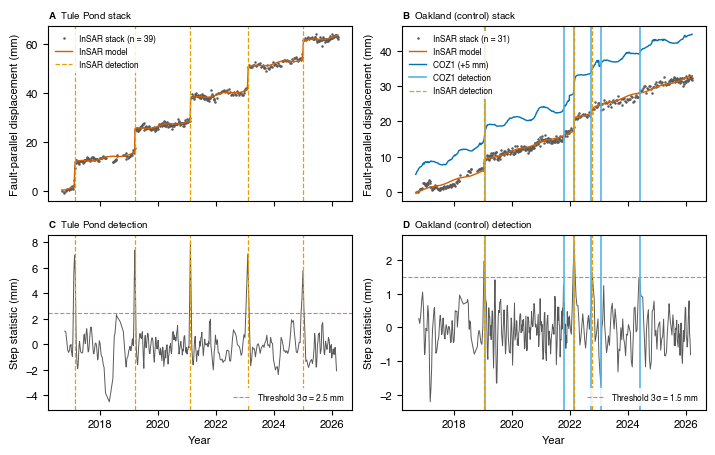

In [7]:
utils.mpl_paper_style(base=8)          # Helvetica, 8 pt, editable PDF text
fig, axes = plt.subplots(2, 2, figsize=(7.2, 4.6), sharex=True)
for j, (title, key, _, _, _, cmcode) in enumerate(SEGS):
    sol = solutions[key]
    # top: the stack, the joint model, the detections
    ax = axes[0, j]
    ax.plot(sol["dates"], sol["stack"] - sol["stack"][0], ".", ms=1.6, color="0.35", label=f"InSAR stack (n = {sol['n']})")
    fitted_step_epochs = []
    for event_fit in sol["fits"]:
        fitted_step_epochs.append(event_fit["step_epoch"])
    model = np.dot(design(sol["dates"], fitted_step_epochs), sol["coef"])   # the joint model fitted above
    ax.plot(sol["dates"], model - sol["stack"][0], "-", lw=1.0, color="#D55E00", label="InSAR model")
    if sol["cm_series"] is not None:
        cm_dates, cm_slip = sol["cm_series"]
        ax.plot(cm_dates, cm_slip - cm_slip[0] + 5.0, "-", lw=1.0, color="#0072B2", label=f"{cmcode} (+5 mm)")
    for i, (detect_yr, stat) in enumerate(sol["cm_detections"]):
        ax.axvline(detect_yr, color="#56B4E9", lw=1.2, label=f"{cmcode} detection" if i == 0 else None)
    for i, (detect_yr, stat) in enumerate(sol["detections"]):
        ax.axvline(detect_yr, color="#E69F00", lw=0.9, ls="--", label="InSAR detection" if i == 0 else None)
    ax.set_ylabel("Fault-parallel displacement (mm)")
    utils.panel_title(ax, "AB"[j], f"{title} stack")
    ax.legend(fontsize=6, loc="upper left")
    # bottom: the step statistic against the threshold
    ax = axes[1, j]
    ax.axhline(k_sigma * sol["stat_sigma"], color="#CC79A7", lw=0.8, ls="--", label=f"Threshold {k_sigma:g}$\\sigma$ = {k_sigma * sol['stat_sigma']:.1f} mm")
    ax.plot(sol["stat_dates"], sol["stat_values"], "-", lw=0.7, color="0.35")
    for detect_yr, stat in sol["cm_detections"]:
        ax.axvline(detect_yr, color="#56B4E9", lw=1.2)
    for detect_yr, stat in sol["detections"]:
        ax.axvline(detect_yr, color="#E69F00", lw=0.9, ls="--")
    ax.set_ylabel("Step statistic (mm)")
    ax.set_xlabel("Year")
    utils.panel_title(ax, "CD"[j], f"{title} detection")
    ax.legend(fontsize=6, loc="lower right")
fig.tight_layout()
f_detect = os.path.join(fig_dir, f"figS_event_detection_{params}_k{k_sigma:g}_win{win_n}.png")
fig.savefig(f_detect, dpi=300)
fig.savefig(f_detect.replace(".png", ".pdf"))
print("Saved figure to:", f_detect)
plt.show()

## 8. Along strike: the joint model at every crossing

The joint model of section 4, with every event of both sections as a step at its `onset_lo` (held fixed),
is fitted at each crossing $x$ that has finite values at more than half of the epochs
(`min_epoch_frac`). It gives the inter-event rate $b_x$ (mm/yr) and the step $A_{k,x}$ (mm) of each event
at that crossing; the along-strike extent of each event is read from these steps. For a section with
event set $E$ (the five Tule Pond events, or the COZ1 control events), the summed event slip, the total
slip and the event-driven fraction are

$$S_x = \sum_{k \in E} A_{k,x}, \qquad T_x = b_x\,T + S_x, \qquad F_x = 100\,\frac{S_x}{T_x},$$

where $T = t_N - t_1$ is the record length (yr), $S_x$ and $T_x$ are in mm and $F_x$ is in %. $F_x$ is
undefined where $|T_x| \le 1$ mm (`total_floor_mm`). It is a ratio of regression coefficients and is not
confined to 0 to 100 %. The profiles are smoothed along the fault with `utils.gaussian_smooth_km`, a
Gaussian of standard deviation 0.4 km (`smooth_km`) on the regular 100 m grid of crossings, whose weights
are renormalised over the finite neighbours; the result is NaN where less than 15 % of the kernel weight
is data, and wherever the input is NaN. The median and the 5 to 95 % range of the unsmoothed $F_x$ over the
crossings within 2 km of each section centre are printed.

In [8]:
gaussian_smooth_km = utils.gaussian_smooth_km      # NaN-aware, gap-preserving Gaussian along the fault (insar_utils)


def interp_nan(x, y):
    """Bridge NaN gaps inside the data range by linear interpolation.

    Parameters
    ----------
    x : ndarray
        Sorted positions (km).
    y : ndarray
        Values, NaN at the gaps.

    Returns
    -------
    ndarray
        Copy of y with the gaps between its first and last finite values filled.
    """
    y = np.asarray(y, float).copy()
    ok = np.isfinite(y)
    if ok.sum() >= 2:
        inner = (x >= x[ok][0]) & (x <= x[ok][-1])
        fill = inner & ~ok
        y[fill] = np.interp(x[fill], x[ok], y[ok])
    return y


# the joint model with every event of both sections, at every crossing (the step epoch of each is onset_lo)
step_epochs_all = creep_events["onset_lo"].to_numpy(float)
segment_of = creep_events["segment"].to_numpy()
design_all = design(dates, step_epochs_all)
inter_event_rate = np.full(len(lats), np.nan)
event_amp = np.full((len(step_epochs_all), len(lats)), np.nan)    # one row per event, one column per crossing
for i in range(len(lats)):
    values = fp_matrix[i]
    ok = np.isfinite(values)
    if ok.sum() < min_epoch_frac * len(dates):
        continue
    coef_i, *_ = np.linalg.lstsq(design_all[ok], values[ok], rcond=None)
    inter_event_rate[i] = coef_i[1]
    event_amp[:, i] = coef_i[4:]

# per section: summed event slip, the event-driven fraction, and the numbers near the centre
# (within the stack half-width, +/- stack_half_km along the trace, as the detection stack)
columns = {"lat": lats, "km": km, "inter_event_rate": inter_event_rate,
           "inter_event_rate_smooth": gaussian_smooth_km(inter_event_rate, km, smooth_km)}
frac_stats = {}
for title, key, fraction_column, _, _, _ in SEGS:
    in_segment = segment_of == key
    event_sum = event_amp[in_segment].sum(axis=0)
    total = inter_event_rate * span + event_sum
    fraction = 100 * event_sum / np.where(np.abs(total) > total_floor_mm, total, np.nan)
    columns[f"event_sum_{fraction_column}"] = event_sum
    columns[f"event_frac_{fraction_column}"] = fraction
    columns[f"event_frac_{fraction_column}_smooth"] = gaussian_smooth_km(fraction, km, smooth_km)
    for j in np.flatnonzero(in_segment):
        columns[f"amp_{step_epochs_all[j]:.3f}"] = event_amp[j]          # the column is named by the event's step epoch
    near_centre = np.abs(km - float(to_km([segments[key]["lat"]])[0])) <= stack_half_km + 1e-6
    fraction_valid = fraction[near_centre & np.isfinite(fraction)]
    frac_stats[key] = dict(n=int(near_centre.sum()), sum_median=float(np.nanmedian(event_sum[near_centre])), median=float(np.median(fraction_valid)),
                           p5=float(np.percentile(fraction_valid, 5)), p95=float(np.percentile(fraction_valid, 95)))
    print(f"{title}: {near_centre.sum()} crossings within the stack half-width; summed event slip median {np.nanmedian(event_sum[near_centre]):.1f} mm; "
          f"fraction median {np.median(fraction_valid):.0f}%, 5-95% {np.percentile(fraction_valid, 5):.0f} to {np.percentile(fraction_valid, 95):.0f}%")
event_fraction = pd.DataFrame(columns)
event_fraction.to_csv(os.path.join(out_dir, "event_fraction_by_crossing.csv"), index=False)

Tule Pond: 40 crossings within the stack half-width; summed event slip median 49.3 mm; fraction median 78%, 5-95% 38 to 95%
Oakland (control): 34 crossings within the stack half-width; summed event slip median 8.2 mm; fraction median 24%, 5-95% 10 to 40%


## 9. The slip above the inter-event rate, and the window around the section

At each crossing a second model is fitted to the inter-event epochs only, the epochs outside every Tule
Pond onset window (at least 10 per crossing):

$$d_x(t_j) = a_x + b_x t_j + c_{1,x} \sin(2\pi t_j) + c_{2,x} \cos(2\pi t_j) + \sum_{k=1}^{5} B_{k,x}\,\rho_k(t_j), \qquad \rho_k(t) = \min\!\left(\max\!\left(\frac{t - t^{\mathrm{lo}}_k}{t^{\mathrm{hi}}_k - t^{\mathrm{lo}}_k},\ 0\right),\ 1\right),$$

where $d_x(t_j)$ is the fault-parallel displacement at crossing $x$ (mm), $a_x$ a constant (mm), $b_x$
the inter-event rate of that crossing (mm/yr), $c_{1,x}$ and $c_{2,x}$ the annual amplitudes (mm),
$t^{\mathrm{lo}}_k$ and $t^{\mathrm{hi}}_k$ the `onset_lo` and `onset_hi` of Tule Pond event $k$ (decimal
years) and $B_{k,x}$ the offset across event $k$ (mm). On the inter-event epochs $\rho_k$ is 0 before the
window and 1 after it, so each event column acts as a step and the offsets between events do not drag the
rate up; no event duration is fitted. The slip above the inter-event rate is then, at every epoch,

$$u_x(t_j) = d_x(t_j) - \left(\hat{a}_x + \hat{b}_x t_j + \hat{c}_{1,x} \sin(2\pi t_j) + \hat{c}_{2,x} \cos(2\pi t_j)\right),$$

in mm, smoothed along the fault at each epoch (0.4 km Gaussian). It is the Hovmöller diagram of Fig 1B.
The 20 km window used for everything along strike is centred on the peak of $u_x$ averaged over the last
five epochs, searched within the Tule Pond search window of `SEGS`, and kept inside the data. The median
of the per-crossing rates $\hat{b}_x$ in the window is printed for the Fig 1 caption.

In [9]:
_, _, tulepond_column, seed_centre_km, half_span_km, _ = SEGS[0]           # Tule Pond
windows = list(zip(tulepond_events["onset_lo"], tulepond_events["onset_hi"]))

# design: constant, rate, annual, and one column per event that is 0 before its onset window and 1 after it.
# Only the inter-event epochs are fitted, so each event column acts as a step that absorbs the event's offset;
# the ramp inside the window touches only the excluded epochs.
ramp_columns = [np.ones_like(dates), dates, np.sin(2 * np.pi * dates), np.cos(2 * np.pi * dates)]
for start, end in windows:
    ramp_columns.append(np.clip((dates - start) / (end - start), 0, 1))
design_ramp = np.column_stack(ramp_columns)
min_inter_event_epochs = 10     # a crossing needs this many finite inter-event epochs
inter_event = np.ones_like(dates, dtype=bool)
for start, end in windows:
    inter_event &= ~((dates >= start) & (dates <= end))
slip_above_rate = np.full_like(fp_matrix, np.nan)
crossing_rates = np.full(fp_matrix.shape[0], np.nan)          # each crossing's own inter-event rate (mm/yr)
for i in range(fp_matrix.shape[0]):
    values = fp_matrix[i]
    ok = np.isfinite(values) & inter_event
    if ok.sum() < min_inter_event_epochs:
        continue
    coef_i = np.linalg.lstsq(design_ramp[ok], values[ok], rcond=None)[0]
    slip_above_rate[i] = values - np.dot(design_ramp[:, :4], coef_i[:4])          # constant, rate and annual subtracted; the steps stay
    crossing_rates[i] = coef_i[1]
for j in range(slip_above_rate.shape[1]):                       # smooth each epoch along the fault
    slip_above_rate[:, j] = gaussian_smooth_km(slip_above_rate[:, j], km, smooth_km)

# re-centre the window on the peak of the cumulative slip at the end of the record
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    final_slip = np.nanmean(slip_above_rate[:, -5:], axis=1)
seed_window = (km >= seed_centre_km - half_span_km) & (km <= seed_centre_km + half_span_km)
peak_km = float(km[seed_window][np.nanargmax(final_slip[seed_window])])
window_centre_km = min(max(peak_km, km.min() + half_span_km), km.max() - half_span_km)     # kept inside the data
w_lo = window_centre_km - half_span_km
w_hi = window_centre_km + half_span_km
# the median of the per-crossing rates over the window, for the Fig 1 caption (each crossing has its own rate removed)
in_window_crossings = (km >= w_lo) & (km <= w_hi)
inter_event_rate_median = float(np.nanmedian(crossing_rates[in_window_crossings]))
print(f"window re-centred on the cumulative-slip peak at {peak_km:.1f} km: {w_lo:.1f} to {w_hi:.1f} km; "
      f"median of the per-crossing inter-event rates in the window {inter_event_rate_median:.2f} mm/yr "
      f"(5-95 %: {np.nanpercentile(crossing_rates[in_window_crossings], 5):.2f} to "
      f"{np.nanpercentile(crossing_rates[in_window_crossings], 95):.2f})")

window re-centred on the cumulative-slip peak at 58.6 km: 48.4 to 68.4 km; median of the per-crossing inter-event rates in the window 4.50 mm/yr (5-95 %: 0.97 to 7.42)


## 10. Section lengths

Two lengths on the Tule Pond profiles, on the north-to-south sorted axis, inside the window of section 9,
with short gaps bridged by linear interpolation.

1. **Length of fault hosting the events.** The cumulative event slip $C_x$ is the summed slip of the five
   Tule Pond events, $S_x$ of section 8, smoothed with the 0.4 km Gaussian. The threshold is the median
   plus 3 robust standard deviations of the same profile on the flanks,

   $$C_{\mathrm{thr}} = \mathrm{median}_{x \in \mathcal{F}}(C_x) + 3\,\sigma_{\mathcal{F}}, \qquad \sigma_{\mathcal{F}} = 1.4826\;\mathrm{median}_{x \in \mathcal{F}} \left|C_x - \mathrm{median}_{x \in \mathcal{F}}(C_x)\right|,$$

   where $\mathcal{F}$ is the set of flank crossings, 52 to 56 km and 64 to 68 km from Point Pinole
   (`flank_km`), and $C_x$, $C_{\mathrm{thr}}$ and $\sigma_{\mathcal{F}}$ are in mm. The length is the
   contiguous run of crossings around the peak of $C_x$ with $C_x \ge C_{\mathrm{thr}}$, from
   $x_{\mathrm{lo}}$ to $x_{\mathrm{hi}}$ (km). The 10-90 % edge width at each end is
   $|x_{10} - x_{90}|$ (km), where $x_{90}$ and $x_{10}$ are the positions at which $C_x$, followed from
   the peak to the north or to the south, first falls below 90 % and 10 % of its peak, interpolated
   linearly between crossings.
2. **Width of the peak slip zone (the 90 % band).** The contiguous run of crossings around the peak of the
   smoothed event-driven fraction $\tilde{F}_x$ (section 8) where

   $$\tilde{F}_x \ge f \max_x \tilde{F}_x,$$

   with $f = 0.90$ (`band_main`, `paper_band_frac` in TulePond_filepaths).

The Oakland control band is found in the same way on the Oakland event-driven fraction, at $f = 0.75$ of
its own peak, inside the Oakland search window of `SEGS`. The extents are saved to `section_lengths.csv`
for the map brackets (notebook 05) and the text.

In [10]:
def contiguous_span(km_axis, values, threshold):
    """Contiguous run of samples around the peak of a profile where it stays at or above a threshold.

    Parameters
    ----------
    km_axis : ndarray
        Sorted along-trace positions (km).
    values : ndarray
        Profile (NaN allowed).
    threshold : float
        Threshold, in the units of values.

    Returns
    -------
    km_lo, km_hi : float
        Positions of the first and last samples of the run (km).
    n : int
        Number of samples in the run.
    """
    peak = int(np.nanargmax(values))
    above = np.isfinite(values) & (values >= threshold)
    lo = peak
    hi = peak
    while lo > 0 and above[lo - 1]:
        lo -= 1
    while hi < len(values) - 1 and above[hi + 1]:
        hi += 1
    return float(km_axis[lo]), float(km_axis[hi]), int(hi - lo + 1)


# everything along strike from here is on the north -> south sorted axis km_sorted
in_window = (km_sorted >= w_lo) & (km_sorted <= w_hi)
cum_event_slip = interp_nan(km_sorted, gaussian_smooth_km(event_fraction[f"event_sum_{tulepond_column}"].values, km, smooth_km)[north_to_south])
cum_event_slip_window = np.where(in_window, cum_event_slip, np.nan)
on_flanks = np.zeros(len(km_sorted), bool)
for flank_lo, flank_hi in flank_km:
    on_flanks |= (km_sorted >= flank_lo) & (km_sorted <= flank_hi)
flank_sigma = utils.robust_sigma(cum_event_slip[on_flanks])
flank_median = np.nanmedian(cum_event_slip[on_flanks])
length_threshold = flank_median + 3 * flank_sigma
peak_cum = float(np.nanmax(cum_event_slip_window))
len_lo, len_hi, len_n = contiguous_span(km_sorted, cum_event_slip_window, length_threshold)
print(f"cumulative event slip: peak {peak_cum:.1f} mm at {km_sorted[np.nanargmax(cum_event_slip_window)]:.1f} km; "
      f"flanks median {flank_median:.1f} mm, robust sigma {flank_sigma:.2f} mm -> threshold {length_threshold:.1f} mm")
print(f"  length of fault hosting the events (above threshold): {len_lo:.1f} to {len_hi:.1f} km = {len_hi - len_lo:.1f} km ({len_n} crossings)")


def level_crossing_km(km_axis, values, level, step):
    """Position at which a profile first falls below a level, followed out from its peak.

    Parameters
    ----------
    km_axis : ndarray
        Along-trace positions, sorted north to south (km).
    values : ndarray
        Profile (mm).
    level : float
        Level (mm).
    step : int
        -1 to go north, +1 to go south.

    Returns
    -------
    float
        Position (km), linear between the last crossing at or above the level and the first below it.
    """
    i = int(np.nanargmax(values))
    while 0 <= i + step < len(values) and np.isfinite(values[i + step]) and values[i + step] >= level:
        i += step
    j = i + step
    assert 0 <= j < len(values) and np.isfinite(values[j]), f"the profile does not fall below {level:.2f} mm inside the window"
    return float(np.interp(level, [values[j], values[i]], [km_axis[j], km_axis[i]]))


edge_widths = {}                         # end -> (km at 90 %, km at 10 %, 10-90 % width km)
for end, step in (("north", -1), ("south", +1)):
    km_90 = level_crossing_km(km_sorted, cum_event_slip_window, 0.9 * peak_cum, step)
    km_10 = level_crossing_km(km_sorted, cum_event_slip_window, 0.1 * peak_cum, step)
    edge_widths[end] = (km_90, km_10, abs(km_10 - km_90))
    print(f"  {end} end: 90% of peak at {km_90:.2f} km, 10% at {km_10:.2f} km: 10-90% edge width {abs(km_10 - km_90):.2f} km")

# the peak slip zone: where the smoothed fraction stays above band_fracs x its peak
fraction_smooth = interp_nan(km_sorted, event_fraction[f"event_frac_{tulepond_column}_smooth"].values[north_to_south])
fraction_window = np.where(in_window, fraction_smooth, np.nan)
peak_frac = float(np.nanmax(fraction_window))
bands = {}
for band_frac in band_fracs:
    band_lo, band_hi, band_n = contiguous_span(km_sorted, fraction_window, band_frac * peak_frac)
    bands[band_frac] = (band_lo, band_hi, band_n)
    print(f"  peak slip zone at {100 * band_frac:.0f}% of the fraction peak ({peak_frac:.0f}%): {band_lo:.1f} to {band_hi:.1f} km = "
          f"{band_hi - band_lo:.1f} km, {band_n} crossings")

# the Oakland control band: 75 % of the peak of its own fraction, inside its search window
_, _, _, coz1_centre_km, coz1_half_span_km, _ = SEGS[1]
coz1_band_frac = 0.75
fraction_coz1 = interp_nan(km_sorted, event_fraction["event_frac_coz1_smooth"].values[north_to_south])
in_window_coz1 = (km_sorted >= coz1_centre_km - coz1_half_span_km) & (km_sorted <= coz1_centre_km + coz1_half_span_km)
fraction_coz1_window = np.where(in_window_coz1, fraction_coz1, np.nan)
coz1_lo, coz1_hi, coz1_n = contiguous_span(km_sorted, fraction_coz1_window, coz1_band_frac * np.nanmax(fraction_coz1_window))

# the measured extents, for the map brackets (notebook 05) and the text
band_lo, band_hi, band_n = bands[band_main]
section_lengths = pd.DataFrame([
    dict(name="tulepond_creep_length", km_lo=len_lo, km_hi=len_hi, lat_lo=lat_of_km(len_hi), lat_hi=lat_of_km(len_lo), n=len_n),
    dict(name="tulepond_band90", km_lo=bands[0.90][0], km_hi=bands[0.90][1], lat_lo=lat_of_km(bands[0.90][1]), lat_hi=lat_of_km(bands[0.90][0]), n=bands[0.90][2]),
    dict(name="oakland_band75", km_lo=coz1_lo, km_hi=coz1_hi, lat_lo=lat_of_km(coz1_hi), lat_hi=lat_of_km(coz1_lo), n=coz1_n)])
section_lengths.to_csv(os.path.join(out_dir, "section_lengths.csv"), index=False)
print("Saved section_lengths.csv")

cumulative event slip: peak 53.7 mm at 58.7 km; flanks median -0.1 mm, robust sigma 2.33 mm -> threshold 6.9 mm
  length of fault hosting the events (above threshold): 56.3 to 62.2 km = 5.9 km (59 crossings)
  north end: 90% of peak at 58.15 km, 10% at 56.15 km: 10-90% edge width 1.99 km
  south end: 90% of peak at 60.30 km, 10% at 62.41 km: 10-90% edge width 2.11 km
  peak slip zone at 90% of the fraction peak (88%): 58.2 to 59.8 km = 1.6 km, 17 crossings
Saved section_lengths.csv


## 11. The band stack: the five events

The mean series of the crossings in the 90 % band,

$$\bar{d}(t_j) = \frac{1}{M_j} \sum_{x \in \mathrm{band}} d_x(t_j),$$

where $M_j$ is the number of band crossings with a finite value at epoch $j$ and $\bar{d}$ is in mm, is
zeroed at its first finite epoch and fitted with the joint model of section 4, with the steps at the five
Tule Pond step epochs (`onset_lo` of `creep_events.csv`) and moving-block bootstrap intervals on the steps.
The steps $A_k$ of this fit are the amplitudes quoted for the five events. The standard deviation across
the band crossings is the grey envelope of Fig 1E. The Oakland control band is stacked in the same way with
the COZ1 control events.

In [11]:
def band_stack(lo_km, hi_km, step_epochs):
    """Mean series of the crossings in a band, with the joint fit and bootstrap intervals on the steps.

    Parameters
    ----------
    lo_km, hi_km : float
        Band limits along the trace (km from Point Pinole).
    step_epochs : sequence of float
        Step epoch of each event (decimal years).

    Returns
    -------
    dict
        n (crossings), mean and std (mm, per epoch; the mean is zeroed at its first finite epoch), coef,
        steps, ci_lo, ci_hi (mm), secular (mm/yr), annual amplitude (mm) and rms (mm) of the fit.
    """
    in_band = (km >= lo_km) & (km <= hi_km)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", RuntimeWarning)
        stack_mean = np.nanmean(fp_matrix[in_band], axis=0)
        stack_std = np.nanstd(fp_matrix[in_band], axis=0)
    ok = np.isfinite(stack_mean)
    stack_mean = stack_mean - stack_mean[ok][0]
    coef, rss = fit_joint(dates[ok], stack_mean[ok], step_epochs)
    ci_lo, ci_hi = bootstrap_amplitudes(dates[ok], stack_mean[ok], step_epochs)
    return dict(n=int(in_band.sum()), mean=stack_mean, std=stack_std, coef=coef, steps=coef[4:], ci_lo=ci_lo, ci_hi=ci_hi,
                secular=float(coef[1]), annual=float(np.hypot(coef[2], coef[3])), rms=float(np.sqrt(rss / ok.sum())))


band_results = {}
for band_frac, (lo_km, hi_km, n_band) in bands.items():
    result = band_stack(lo_km, hi_km, step_epochs_tulepond)
    band_results[band_frac] = result
    print(f"band {100 * band_frac:.0f}%: {lo_km:.1f} to {hi_km:.1f} km, n = {result['n']} crossings; secular {result['secular']:.2f} mm/yr, "
          f"annual {result['annual']:.2f} mm, rms {result['rms']:.2f} mm")
    for step_epoch, step, ci_lo, ci_hi in zip(step_epochs_tulepond, result["steps"], result["ci_lo"], result["ci_hi"]):
        print(f"    {step_epoch:.3f}: {step:5.2f} mm  [{ci_lo:.2f}, {ci_hi:.2f}]")
    print(f"    sum {np.sum(result['steps']):.1f} mm, mean {np.mean(result['steps']):.1f} mm, "
          f"range {np.min(result['steps']):.1f} to {np.max(result['steps']):.1f} mm")
    print("")
step_epochs_coz1 = coz1_events["onset_lo"].to_numpy(float)          # every COZ1 control event (section 5)
coz1_band = band_stack(coz1_lo, coz1_hi, step_epochs_coz1)
print(f"control, Oakland 75% band {coz1_lo:.1f} to {coz1_hi:.1f} km (n = {coz1_band['n']}): steps "
      f"{np.round(coz1_band['steps'], 2).tolist()} mm, secular {coz1_band['secular']:.2f} mm/yr")

band 90%: 58.2 to 59.8 km, n = 17 crossings; secular 0.96 mm/yr, annual 0.78 mm, rms 1.18 mm
    2017.099: 10.69 mm  [8.85, 12.18]
    2019.186: 10.47 mm  [8.99, 12.00]
    2021.107: 11.25 mm  [9.85, 12.60]
    2023.080: 11.73 mm  [10.30, 13.14]
    2024.984:  7.74 mm  [6.45, 9.01]
    sum 51.9 mm, mean 10.4 mm, range 7.7 to 11.7 mm



control, Oakland 75% band 32.9 to 33.6 km (n = 8): steps [3.17, 6.15, 3.75] mm, secular 2.10 mm/yr


## 12. The slip budget, the alignment arrays and the creepmeters

At each crossing the event-driven rate and the total rate are

$$r^{\mathrm{ev}}_x = \frac{S_x}{T}, \qquad r^{\mathrm{tot}}_x = b_x + r^{\mathrm{ev}}_x,$$

where $S_x$ is the summed step of the section's own events (mm, section 8), $T$ the record length (yr),
$b_x$ the inter-event rate (mm/yr), and both rates are in mm/yr. Fig 1C, 1D and the Tule Pond blocks count
the five Tule Pond events only; the Oakland control block counts all of its own COZ1 events. Both sets of
steps stay in the joint model at every crossing (section 8). For Fig 1C the profiles are smoothed with a
0.2 km Gaussian (`profile_smooth_km`). A block, the span of crossings from $x_{\mathrm{lo}}$ to
$x_{\mathrm{hi}}$, reports the means of $b_x$, $r^{\mathrm{ev}}_x$ and $r^{\mathrm{tot}}_x$ over its
crossings and the event-driven share $100\,\overline{r^{\mathrm{ev}}} / \overline{r^{\mathrm{tot}}}$ (%).

The alignment arrays (McFarland et al. 2017) within 2 km of the trace enter twice. Each is refit over the
InSAR window by an ordinary least-squares line through the surveys inside it, if there are at least 4
surveys spanning at least 5 yr (dark grey in Fig 1, black in the supplement); its 1-sigma error is the
standard error of the slope, from the scatter of the surveys about the line. The archive's whole-record
rate is also shown (grey). A block is compared with the mean of the arrays within 1 km of it.

The creepmeter rates (Langbein et al. 2024) are least-squares slopes of the daily records over the InSAR
window. Daily samples are not independent, so their 1-sigma error comes from the slip gained in each whole
year from the first sample (`utils.annual_increment_rate`):

$$\Delta y_m = y(t_1 + m) - y(t_1 + m - 1), \quad m = 1, \ldots, M, \qquad \sigma_r = \frac{\mathrm{std}(\Delta y)}{\sqrt{M}},$$

where $y$ is the creepmeter slip (mm) interpolated linearly to whole years after the first sample $t_1$,
$M$ the number of whole years, std the sample standard deviation (one degree of freedom removed) and
$\sigma_r$ the 1-sigma error of the rate (mm/yr). The mean of $\Delta y_m$ must agree with the fitted rate
within 0.5 mm/yr (asserted).

In [12]:
# the step columns of the five Tule Pond events (section 8 names each by its step epoch)
tulepond_amp_columns = []
for step_epoch in step_epochs_tulepond:
    column = f"amp_{step_epoch:.3f}"
    assert column in event_fraction.columns, f"no per-crossing step column {column} for the Tule Pond event"
    tulepond_amp_columns.append(column)
slip_budget = event_fraction[["lat", "km"]].copy()
slip_budget["secular"] = event_fraction["inter_event_rate"]
slip_budget["event_sum"] = event_fraction[tulepond_amp_columns].sum(axis=1, min_count=1)      # Tule Pond events only
slip_budget["event_rate"] = slip_budget["event_sum"] / span
slip_budget["total"] = slip_budget["secular"] + slip_budget["event_rate"]
# the Oakland control block counts its own events instead, all of them (each block counts the events of its own section)
coz1_amp_columns = []
for step_epoch in step_epochs_coz1:
    column = f"amp_{step_epoch:.3f}"
    assert column in event_fraction.columns, f"no per-crossing step column {column} for the Oakland event"
    coz1_amp_columns.append(column)
slip_budget["event_rate_oakland"] = event_fraction[coz1_amp_columns].sum(axis=1, min_count=1) / span
slip_budget["total_oakland"] = slip_budget["secular"] + slip_budget["event_rate_oakland"]
slip_budget = slip_budget.sort_values("km").reset_index(drop=True)
for name in ("secular", "event_rate", "total"):
    slip_budget[f"{name}_smooth"] = gaussian_smooth_km(slip_budget[name].values, slip_budget["km"].values, profile_smooth_km)   # = Fig 1C

# alignment arrays within aa_max_dist_km of the trace: refit over the InSAR window and the archive's whole-record rate
# Every array must load (a missing or unreadable survey file stops the notebook).
aa_summary = utils.load_aa_summary(common_paths["aa_summary"])
aa_summary = utils.project_to_fault(aa_summary, x_fault, lon_col="long_deg", lat_col="lat_deg")
aa_rows = []
for _, site in aa_summary.iterrows():
    if abs(site.dist_fault_km) > aa_max_dist_km:
        continue
    array = utils.load_aa(common_paths["aa_dir"], site.site_code)
    surveys_in_window = array[(array.year >= t0) & (array.year <= t1)]
    if len(surveys_in_window) > 0:
        span_in_window = surveys_in_window.year.max() - surveys_in_window.year.min()
    else:
        span_in_window = 0.0
    if len(surveys_in_window) >= aa_min_surveys and span_in_window >= aa_min_span_yr:
        rate_window, _, rate_window_se, _ = utils.linear_rate(surveys_in_window.year.values, surveys_in_window.cum_mm.values)
    else:
        rate_window = np.nan
        rate_window_se = np.nan
    aa_rows.append(dict(code=site.site_code, name=site.site_name, lat=site.lat_deg, lon=site.long_deg, km=float(to_km([site.lat_deg])[0]),
                        rate_window=rate_window, rate_window_se=rate_window_se, n_window=len(surveys_in_window), span_window=span_in_window,
                        rate_longterm=float(site["rate_lnrr"]), first_yr=float(site["first_yr"]), last_yr=float(site["last_yr"])))
aa_rates = pd.DataFrame(aa_rows).sort_values("km")
print(f"{len(aa_rates)} Hayward arrays within {aa_max_dist_km:g} km of the trace; {aa_rates.rate_window.notna().sum()} refit over the InSAR window")

# creepmeter rates over the InSAR window: code -> (km, mm/yr), and their 1-sigma from the whole-year gains
cm_rates = {}
cm_rate_sigma = {}
for code, lat, lon, name in creepmeters:
    cm_dates, cm_slip = utils.daily_creepmeter(common_paths["creepmeter_dir"], code, t0, t1, creepmeter_glitches)
    km_cm = float(to_km([lat])[0])
    rate_cm = utils.linear_rate(cm_dates, cm_slip)[0]
    cm_rates[code] = (km_cm, rate_cm)
    mean_gain, cm_rate_sigma[code], n_years = utils.annual_increment_rate(cm_dates, cm_slip)
    assert abs(mean_gain - rate_cm) < 0.5, f"{code}: mean yearly gain {mean_gain:.2f} vs fitted rate {rate_cm:.2f} mm/yr"
    print(f"  creepmeter {code}: {rate_cm:.2f} +/- {cm_rate_sigma[code]:.2f} mm/yr (1 sigma, {n_years} whole years; mean yearly gain {mean_gain:.2f})")
in_section = aa_rates[(aa_rates.km >= len_lo - 1.0) & (aa_rates.km <= len_hi + 1.0) & aa_rates.rate_window.notna()]   # as budget_block
aa_window_text = f"{utils.decimal_year_to_day(t0).date()} to {utils.decimal_year_to_day(t1).date()}"   # the InSAR window
print(f"  arrays at Tule Pond ({len_lo - 1:.1f}-{len_hi + 1:.1f} km), refit over the InSAR window {aa_window_text}, +/- 1 sigma (mm/yr):")
assert len(in_section) > 0, "no alignment array with a window refit along the Tule Pond section"
for array_row in in_section.itertuples():
    print(f"    {array_row.code} {array_row.rate_window:.2f} +/- {array_row.rate_window_se:.2f} ({array_row.n_window} surveys)")


def budget_block(name, lo, hi, event_column="event_rate", total_column="total"):
    """Mean rates of the crossings in a block, and of the alignment arrays within 1 km of it.

    Parameters
    ----------
    name : str
        Block name, printed and stored.
    lo, hi : float
        Block limits along the trace (km from Point Pinole).
    event_column, total_column : str
        Columns of slip_budget with the event-driven and total rates (the Tule Pond events by default;
        the Oakland control block passes its own).

    Returns
    -------
    dict
        Mean inter-event, event-driven and total rates (mm/yr), the event-driven share (%), and the mean
        window and whole-record rates of the nearby arrays (mm/yr) with their counts.
    """
    in_block = (slip_budget.km >= lo) & (slip_budget.km <= hi)
    arrays_near = aa_rates[(aa_rates.km >= lo - 1.0) & (aa_rates.km <= hi + 1.0)]
    block = dict(name=name, lo=lo, hi=hi, n=int(in_block.sum()),
                 secular=float(slip_budget.loc[in_block, "secular"].mean()), event_rate=float(slip_budget.loc[in_block, event_column].mean()),
                 total=float(slip_budget.loc[in_block, total_column].mean()),
                 frac_pct=100 * slip_budget.loc[in_block, event_column].mean() / max(slip_budget.loc[in_block, total_column].mean(), 1e-9),
                 aa_window_mean=float(arrays_near.rate_window.mean()), aa_window_n=int(arrays_near.rate_window.notna().sum()),
                 aa_longterm_mean=float(arrays_near.rate_longterm.mean()), aa_n=len(arrays_near))
    print(f"[{name}] {lo:.1f} to {hi:.1f} km, n = {block['n']}: secular {block['secular']:.2f}, event-driven {block['event_rate']:.2f}, "
          f"total {block['total']:.2f} mm/yr ({block['frac_pct']:.0f}% event-driven); arrays: window {block['aa_window_mean']:.2f} "
          f"(n {block['aa_window_n']}), long-term {block['aa_longterm_mean']:.2f} (n {block['aa_n']}) mm/yr")
    return block


budget = {}
for band_frac, (lo_km, hi_km, n_band) in bands.items():
    budget[f"band{int(band_frac * 100)}"] = budget_block(f"Tule Pond {100 * band_frac:.0f}% band", lo_km, hi_km)
budget["length"] = budget_block("Tule Pond, length hosting events", len_lo, len_hi)
budget["flanks"] = budget_block("Tule Pond band +/- 5 km (band included)", band_lo - 5.0, band_hi + 5.0)   # key name kept for the registry
budget["coz1"] = budget_block(f"Oakland control 75% band (its own {len(step_epochs_coz1)} events)", coz1_lo, coz1_hi,
                              event_column="event_rate_oakland", total_column="total_oakland")

  AA HAPP: 3 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 1995.007 vs 1/28/1995, 1996.820 vs 10/22/1996, 2024.680 vs 10/5/2024; 0 without a readable date
  AA HCCD: 1 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2023.841 vs 12/3/2023; 0 without a readable date
  AA HDST: 1 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 1988.563 vs 6/24/1988; 0 without a readable date
  AA HDWT: 3 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2015.721 vs 10/20/2015, 2017.782 vs 10/14/2017, 2018.782 vs 10/14/2018; 0 without a readable date
  AA HFLO: 2 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2017.782 vs 10/14/2017, 2018.782 vs 10/14/2018; 0 without a readable date


  AA HFMT: 13 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 1997.600 vs 8/17/1997, 1998.700 vs 8/30/1998, 1999.700 vs 8/29/1999, 2000.800 vs 10/28/2000, 2001.800 vs 10/26/2001, 2002.800 vs 11/6/2002, 2003.800 vs 10/23/2003, 2004.800 vs 10/16/2004, 2005.800 vs 10/8/2005, 2006.800 vs 10/28/2006, 2007.900 vs 11/9/2007, 2008.900 vs 11/7/2008, 2009.800 vs 10/17/2009; 0 without a readable date
  AA HLSA: 1 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2018.782 vs 10/14/2018; 0 without a readable date


  AA HPIN: 1 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2023.910 vs 11/26/2023; 0 without a readable date
  AA HPMD: 0 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year); 1 without a readable date


  AA HROS: 1 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2023.729 vs 9/26/2023; 0 without a readable date


  AA HSGR: 2 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2012.746 vs 9/23/2012, 2015.672 vs 10/5/2015; 0 without a readable date
  AA HTBR: 1 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2002.543 vs 7/14/2002; 0 without a readable date


  AA HWDL: 1 surveys whose archive year and date disagree by > 1.5 d after the 1-day correction (kept at the archive year): 2024.680 vs 10/5/2024; 0 without a readable date
33 Hayward arrays within 2 km of the trace; 30 refit over the InSAR window


  CPP1: 2 listed glitch days dropped of 3420: 2017-05-18 to 2017-05-18 (1 d: two 10-min samples at -283.7 mm (~340 mm below the record) pull the daily mean down 4.8 mm); 2018-02-12 to 2018-02-12 (1 d: one 10-min sample at -283.7 mm (~350 mm below the record) pulls the daily mean down 2.4 mm)
  creepmeter CPP1: 5.05 +/- 0.37 mm/yr (1 sigma, 9 whole years; mean yearly gain 5.22)


  CTM1: 0 listed glitch days dropped of 3225
  creepmeter CTM1: 4.11 +/- 0.22 mm/yr (1 sigma, 9 whole years; mean yearly gain 4.13)


  COZ1: 0 listed glitch days dropped of 3484
  creepmeter COZ1: 4.43 +/- 1.01 mm/yr (1 sigma, 9 whole years; mean yearly gain 4.14)


  CHP1: 0 listed glitch days dropped of 3353
  creepmeter CHP1: 3.81 +/- 0.08 mm/yr (1 sigma, 9 whole years; mean yearly gain 3.81)


  CFW1: 0 listed glitch days dropped of 3437
  creepmeter CFW1: 6.99 +/- 0.73 mm/yr (1 sigma, 9 whole years; mean yearly gain 6.99)
  arrays at Tule Pond (55.3-63.2 km), refit over the InSAR window 2016-09-03 to 2026-03-21, +/- 1 sigma (mm/yr):
    HGIL 6.88 +/- 0.55 (8 surveys)
    HRKT 6.96 +/- 0.37 (9 surveys)
    HHAN 6.81 +/- 0.18 (8 surveys)
    HUNI 7.20 +/- 0.35 (8 surveys)
[Tule Pond 90% band] 58.2 to 59.8 km, n = 17: secular 0.88, event-driven 5.56, total 6.44 mm/yr (86% event-driven); arrays: window 6.88 (n 1), long-term 6.08 (n 1) mm/yr
[Tule Pond, length hosting events] 56.3 to 62.2 km, n = 59: secular 2.73, event-driven 3.71, total 6.44 mm/yr (58% event-driven); arrays: window 6.96 (n 4), long-term 6.32 (n 4) mm/yr
[Tule Pond band +/- 5 km (band included)] 53.2 to 64.8 km, n = 107: secular 4.05, event-driven 2.32, total 6.36 mm/yr (36% event-driven); arrays: window 6.92 (n 8), long-term 6.39 (n 8) mm/yr
[Oakland control 75% band (its own 3 events)] 32.9 to 33.6 km, n = 8:

## 13. Seismicity near the section

The earthquakes are from the GrowClust relocated catalogue of the Hayward area [citation needed], which
holds the relocated events and the unrelocated NCSS events; an event counts as relocated where
`source == "growclust"`. The repeating earthquakes are from the Taira GEN3 catalogue [citation needed] and
from Waldhauser and Schaff (2021). Each event is placed along strike at the distance of its nearest trace
vertex. The counts quoted in the discussion (registered) are the earthquakes (all, and the relocated ones)
and the repeating earthquakes within `seis_max_dist_km` (2 km) of the trace, from the first to the last
InSAR acquisition (`t0`, `t1`), inside (a) the section hosting the events (`len_lo` to `len_hi`, section
10) and (b) the 90 % band (`band_main`). The two repeater catalogues are also counted separately. They
overlap in time and may list the same earthquake, so their sum is an upper bound.

In [13]:
seis = utils.load_growclust_catalog(common_paths["growclust_cat"], bbox=common_paths["aoi_bbox"])
seis = utils.project_to_fault(seis, x_fault)
seis = seis[(seis.dist_fault_km.abs() <= seis_max_dist_km) & (seis.YYYY >= t0) & (seis.YYYY <= t1)].copy()
seis["km"] = to_km(seis["ft_lat"].values)

cre = pd.concat([utils.load_cre_taira(common_paths["CRE_Taira"]), utils.load_cre_waldhauser(common_paths["CRE_Wald"])], ignore_index=True)
cre = cre.dropna(subset=["YYYY", "Lon", "Lat", "Mag"])
west, south, east, north = common_paths["aoi_bbox"]
cre = cre[(cre.Lon >= west) & (cre.Lon <= east) & (cre.Lat >= south) & (cre.Lat <= north)]
cre = utils.project_to_fault(cre, x_fault)
cre = cre[(cre.dist_fault_km.abs() <= seis_max_dist_km) & (cre.YYYY >= t0) & (cre.YYYY <= t1)].copy()
cre["km"] = to_km(cre["ft_lat"].values)

seis_window = seis[(seis.km >= w_lo) & (seis.km <= w_hi)]
cre_window = cre[(cre.km >= w_lo) & (cre.km <= w_hi)]
n_seis_win = len(seis_window)
n_cre_win = len(cre_window)
n_cre_band = int(((cre.km >= band_lo) & (cre.km <= band_hi)).sum())
print(f"within {seis_max_dist_km:g} km of the trace, {t0:.1f} to {t1:.1f}: {len(seis)} earthquakes ({(seis.source == 'growclust').sum()} relocated) "
      f"and {len(cre)} repeaters on the whole fault; in the Tule Pond window ({w_lo:.0f} to {w_hi:.0f} km): {n_seis_win} earthquakes, "
      f"{n_cre_win} repeaters; in the {100 * band_main:.0f}% band: {n_cre_band} repeaters")

# the counts the discussion quotes: the section hosting the events and the paper's band, over the InSAR period
band_tag = f"band{int(round(100 * band_main))}"                    # 'band90', as the other 04 keys
seis_count_spans = {"section": (len_lo, len_hi), band_tag: (band_lo, band_hi)}
seis_counts = {}                                                    # (span, quantity) -> count
for span_name, (span_lo, span_hi) in seis_count_spans.items():
    seis_in = seis[(seis.km >= span_lo) & (seis.km <= span_hi)]
    cre_in = cre[(cre.km >= span_lo) & (cre.km <= span_hi)]
    seis_counts[(span_name, "seis_all")] = len(seis_in)
    seis_counts[(span_name, "seis_reloc")] = int((seis_in.source == "growclust").sum())
    seis_counts[(span_name, "cre_all")] = len(cre_in)
    seis_counts[(span_name, "cre_taira")] = int((cre_in.cat == "Taira26").sum())
    seis_counts[(span_name, "cre_wald")] = int((cre_in.cat == "Waldhauser21").sum())
    assert seis_counts[(span_name, "cre_taira")] + seis_counts[(span_name, "cre_wald")] == len(cre_in), "a repeater of neither catalogue"
assert seis_counts[(band_tag, "cre_all")] == n_cre_band, "the band count differs from the one registered as 04_n_cre_band"
catalogue_spans = (f"GrowClust {seis.YYYY.min():.2f}-{seis.YYYY.max():.2f}" if len(seis) else "GrowClust: none in the window",
                   f"repeaters " + ", ".join(f"{name} {grp.YYYY.min():.2f}-{grp.YYYY.max():.2f}" for name, grp in cre.groupby("cat")))
seis_count_lines = []
for span_name, (span_lo, span_hi) in seis_count_spans.items():
    seis_count_lines.append(f"{span_name} ({span_lo:.1f}-{span_hi:.1f} km), within {seis_max_dist_km:g} km of the trace, {t0:.2f}-{t1:.2f}: "
                            f"{seis_counts[(span_name, 'seis_all')]} earthquakes ({seis_counts[(span_name, 'seis_reloc')]} relocated), "
                            f"{seis_counts[(span_name, 'cre_all')]} repeating earthquakes (Taira GEN3 {seis_counts[(span_name, 'cre_taira')]}, "
                            f"Waldhauser and Schaff {seis_counts[(span_name, 'cre_wald')]}; may overlap)")
print("\n".join(seis_count_lines))
print("events in the window by catalogue span: " + "; ".join(catalogue_spans))

within 2 km of the trace, 2016.7 to 2026.2: 1937 earthquakes (1670 relocated) and 145 repeaters on the whole fault; in the Tule Pond window (48 to 68 km): 231 earthquakes, 17 repeaters; in the 90% band: 0 repeaters
section (56.3-62.2 km), within 2 km of the trace, 2016.67-2026.22: 57 earthquakes (42 relocated), 4 repeating earthquakes (Taira GEN3 4, Waldhauser and Schaff 0; may overlap)
band90 (58.2-59.8 km), within 2 km of the trace, 2016.67-2026.22: 10 earthquakes (8 relocated), 0 repeating earthquakes (Taira GEN3 0, Waldhauser and Schaff 0; may overlap)
events in the window by catalogue span: GrowClust 2016.67-2025.99; repeaters Taira26 2016.90-2025.98


## 14. Fig 1 inputs: the rotated map, the Hovmöller diagram, the per-event profiles, the rates and the stack

Fig 1 is drawn in notebook 14. This section computes what it shows and writes it to one file,
`fig1_inputs.npz`.

The map is the fault-parallel velocity (notebook 02) sampled on a longitude-latitude grid and referenced,
for display only, to the CTM1-COZ1 patch, so that the fault sits at zero. The reference is the mid-point of
the medians of the two blocks within 5 km of the fault in that patch. The Hovmöller diagram is the slip
above the inter-event rate $u_x(t)$ of section 9 on a regular 6 day grid (GMT grids must be regular), each
node taking the nearest acquisition and left blank where none lies within 9 d. The per-event profiles are
the running sums of the five per-crossing steps $A_{k,x}$ of section 8 along strike, smoothed with the
0.2 km Gaussian. The creep rates are the smoothed inter-event, event-driven and total rates of section 12
in the window, with the 5 to 95 % range of the per-crossing rates within 0.5 km along the trace, kept only
where at least 5 crossings have a rate. The band stack is the mean series of section 11 with its joint
model, split into the epochs between events and the epochs next to each step.

The file also holds the trace, the EPSG code and the map strike (notebook 14 rebuilds the strike frame from
them), the window and band limits, the earthquakes and repeating earthquakes in the window (section 13),
the alignment-array rates (section 12), the creepmeter rates with their 1-sigma errors, and a provenance
string.

In [14]:
# --- the strike frame of the map: u along the mean strike from Point Pinole (km, + south), v across the fault (km, + east)
with h5py.File(map_file, "r") as hf:
    fp_map = hf["fp_velocity"][:].astype(float)
    attrs = {}
    for attr_name, attr_value in hf.attrs.items():
        if isinstance(attr_value, bytes):
            attrs[attr_name] = attr_value.decode()
        else:
            attrs[attr_name] = str(attr_value)
fp_map[fp_map == 0] = np.nan
frame = utils.strike_frame(int(attrs["EPSG"]), strike_map, x_fault["ft_lon"].values, x_fault["ft_lat"].values)   # u along strike from Point Pinole, v across

# Notebook 14 draws the map with utils.fault_map_panel (the same panel as the 05 and 11 supplements): GMT's
# oblique Mercator, x axis along strike_map - 90 (north-east, across the fault), so the fault runs up the page
# with north at the top. The grid covers the rectangle of the strike frame that utils.fault_map_corners gives:
# u from -3 km (north of Point Pinole) to 70 km (just south of CFW1), v +/- 10.9 km.
_, _, corners = utils.fault_map_corners(frame)                    # (lon, lat) of the four map corners

# --- a) the FP velocity on a regular lon/lat grid (nearest UTM pixel), referenced in the strike frame
lon_axis, lat_axis, fp_lonlat = utils.utm_grid_to_lonlat(fp_map, float(attrs["X_FIRST"]), float(attrs["X_STEP"]),
                                                         float(attrs["Y_FIRST"]), float(attrs["Y_STEP"]), frame["to_utm"], corners)
lon_grid, lat_grid = np.meshgrid(lon_axis, lat_axis)
u_grid, v_grid = utils.to_uv(frame, lon_grid, lat_grid)                    # strike-frame coordinates of the grid nodes
# creepmeter positions along u (the distance of each instrument from the nearest trace vertex is printed)
u_creepmeter, creepmeter_offset_m = utils.creepmeter_u_km(frame, x_fault["ft_lon"].values, x_fault["ft_lat"].values, creepmeters)
for code, distance_m in creepmeter_offset_m.items():
    print(f"  {code}: {distance_m:.0f} m from the nearest trace vertex")
patch_lo, patch_hi = sorted([u_creepmeter["CTM1"], u_creepmeter["COZ1"]])
# display reference: the mid-point of the two blocks' medians in the CTM1-COZ1 patch, so the
# fault sits at zero and the colour scale swings equally blue (west) and red (east)
in_patch = (u_grid >= patch_lo) & (u_grid <= patch_hi)
fp_west = np.nanmedian(fp_lonlat[in_patch & (v_grid < 0) & (v_grid >= -ref_patch_km)])
fp_east = np.nanmedian(fp_lonlat[in_patch & (v_grid > 0) & (v_grid <= ref_patch_km)])
fp_lonlat = fp_lonlat - 0.5 * (fp_west + fp_east)
print(f"map display reference: west block {fp_west:+.2f}, east block {fp_east:+.2f} mm/yr; mid-point removed")

# --- b) the hovmoller: the slip above the inter-event rate in the window, on a regular 6-day time grid
in_window_rows = (km >= w_lo) & (km <= w_hi)
south_to_north = np.argsort(km[in_window_rows])
grid = np.arange(w_lo, w_hi + 0.05, 0.1)                                         # 100 m rows
hov_rows = np.full((grid.size, slip_above_rate.shape[1]), np.nan)
grid_index = np.round((km[in_window_rows][south_to_north] - grid[0]) / 0.1).astype(int)
on_grid = (grid_index >= 0) & (grid_index < grid.size)
hov_rows[grid_index[on_grid]] = slip_above_rate[in_window_rows][south_to_north][on_grid]
with warnings.catch_warnings():
    warnings.simplefilter("ignore", RuntimeWarning)
    vmax = max(float(np.nanpercentile(slip_above_rate[in_window_rows], 99.5)), 1.0)
vmin = -neg_floor_frac * vmax
t_regular = np.arange(t0, t1 + 1e-9, 6.0 / 365.25)
nearest_epoch = np.zeros(t_regular.size, int)                                    # the real epoch nearest each 6-day node
for node, t_node in enumerate(t_regular):
    nearest_epoch[node] = int(np.argmin(np.abs(dates - t_node)))
hovmoller = hov_rows[:, nearest_epoch]
hovmoller[:, np.abs(t_regular - dates[nearest_epoch]) > 9.0 / 365.25] = np.nan     # no real epoch within 9 d: blank

# --- c) per-event cumulative slip profiles along strike: the per-crossing steps of the joint fit of section 8 (event_fraction,
# the same crossings and fit as D), smoothed and bridged across gaps as D
km_window = km[in_window_rows][south_to_north]
event_amp_window = np.column_stack([event_fraction[column].values[in_window_rows][south_to_north] for column in tulepond_amp_columns])
cum_prof = np.zeros((step_epochs_tulepond.size, km_window.size))
running = np.zeros(km_window.size)
for i in range(step_epochs_tulepond.size):
    running = running + np.nan_to_num(interp_nan(km_window, gaussian_smooth_km(event_amp_window[:, i], km_window, profile_smooth_km)))
    cum_prof[i] = running

# --- d) the creep rates of D on the window, south to north: the smoothed rates bridged across gaps as C, and the 5-95 %
# range of the per-crossing rates within +/- rate_band_half_km (NaN with fewer than rate_band_min_n crossings: not bridged,
# so the shading shows where crossings exist)
budget_window = slip_budget[(slip_budget.km >= w_lo) & (slip_budget.km <= w_hi)].sort_values("km")
km_budget = budget_window.km.values
rate_lines = {}
rate_bands = {}
for name in ("secular", "event_rate", "total"):
    rate_lines[name] = interp_nan(km_budget, budget_window[f"{name}_smooth"].values)
    per_crossing = budget_window[name].values
    band_lo_hi = np.full((km_budget.size, 2), np.nan)
    for j, km_j in enumerate(km_budget):
        near = np.abs(km_budget - km_j) <= rate_band_half_km + 1e-6
        values_near = per_crossing[near & np.isfinite(per_crossing)]
        if values_near.size >= rate_band_min_n:
            band_lo_hi[j] = np.percentile(values_near, [5, 95])
    rate_bands[name] = band_lo_hi

# --- the band stack's model, split into inter-event (bluish green) and event (orange) epochs for panel E
band_main_stack = band_results[band_main]
model_full = np.dot(design(dates, step_epochs_tulepond), band_main_stack["coef"])
is_event_epoch = np.zeros(dates.size, bool)
for step_epoch in step_epochs_tulepond:
    j = int(np.searchsorted(dates, step_epoch))
    if 0 < j < dates.size:
        is_event_epoch[j] = True
event_epochs_wide = is_event_epoch.copy()
event_epochs_wide[1:] |= is_event_epoch[:-1]
event_epochs_wide[:-1] |= is_event_epoch[1:]

# --- everything Fig 1 draws, in one file for notebook 14
cm_codes = list(cm_rates.keys())                                    # creepmeter order of TulePond_filepaths
fig1_in = dict(
    # A) the map: the referenced grid, its axes, and what rebuilds the strike frame (EPSG, strike, trace)
    fp_lonlat=fp_lonlat, lon_axis=lon_axis, lat_axis=lat_axis, epsg=int(attrs["EPSG"]), strike_map=strike_map,
    trace_lon=x_fault["ft_lon"].to_numpy(float), trace_lat=x_fault["ft_lat"].to_numpy(float),
    len_lo=len_lo, len_hi=len_hi,
    # B) the Hovmöller diagram, its colour limits, the window, the band and the catalogues in the window
    hovmoller=hovmoller, hov_km=grid, t_regular=t_regular, vmin=vmin, vmax=vmax,
    t0=t0, t1=t1, w_lo=w_lo, w_hi=w_hi, band_lo=band_lo, band_hi=band_hi, band_main=band_main,
    seis_yr=seis_window.YYYY.to_numpy(float), seis_km=seis_window.km.to_numpy(float),
    seis_mag=seis_window.Mag.to_numpy(float), seis_depth=seis_window.Depth.to_numpy(float),
    cre_yr=cre_window.YYYY.to_numpy(float), cre_km=cre_window.km.to_numpy(float),
    # C) the per-event cumulative profiles
    cum_prof=cum_prof, km_window=km_window, step_epochs=step_epochs_tulepond,
    # D) the creep rates, the alignment arrays and the creepmeters
    km_budget=km_budget, rate_band_half_km=rate_band_half_km, span=span,
    aa_km=aa_rates.km.to_numpy(float), aa_rate_window=aa_rates.rate_window.to_numpy(float),
    aa_rate_window_se=aa_rates.rate_window_se.to_numpy(float),
    cm_codes=np.array(cm_codes), cm_km=np.array([cm_rates[code][0] for code in cm_codes], float),
    cm_rate=np.array([cm_rates[code][1] for code in cm_codes], float),
    cm_rate_sigma=np.array([cm_rate_sigma[code] for code in cm_codes], float),
    # E) the band stack and its model
    dates=dates, stack_mean=band_main_stack["mean"], stack_std=band_main_stack["std"], stack_n=band_main_stack["n"],
    stack_secular=band_main_stack["secular"], stack_steps=band_main_stack["steps"],
    model_full=model_full, is_event_epoch=is_event_epoch, event_epochs_wide=event_epochs_wide)
for name in ("secular", "event_rate", "total"):
    fig1_in[f"rate_line_{name}"] = rate_lines[name]
    fig1_in[f"rate_band_{name}"] = rate_bands[name]
f_fig1_in = os.path.join(out_dir, "fig1_inputs.npz")
np.savez_compressed(f_fig1_in, provenance=utils.provenance_stamp(notebook, repo_dir), **fig1_in)
print("wrote", f_fig1_in)

  CPP1: 39 m from the nearest trace vertex
  CTM1: 14 m from the nearest trace vertex
  COZ1: 56 m from the nearest trace vertex
  CHP1: 44 m from the nearest trace vertex
  CFW1: 26 m from the nearest trace vertex
map display reference: west block +1.31, east block +5.79 mm/yr; mid-point removed


wrote /Users/dlindsay/work/proj_TulePond_DISP/outputs/04_event_detection/fig1_inputs.npz


## 15. Figure: the creep rate along the whole fault (supplement)

Three panels on one along-fault axis, every profile smoothed with the same 0.5 km Gaussian (`rate_smooth_km`, as the
rate profile of notebook 03) and the Tule Pond section shaded. (A) The cross-fault azimuth of the mapped trace at every 100 m
crossing. (B) The fault-parallel creep rate of every crossing kept by notebook 03 (`creep_rate_fp.csv`; crossings
flagged by its along-fault rate test are not shown), the creepmeter rates over the InSAR window, and the interseismic
Hayward Fault rates of the Johnson et al. (2022) compilation (alignment arrays, InSAR and cultural offsets, 1 sigma).
(C) The slip budget: the inter-event, event-driven (five Tule Pond events) and total rates, with the creepmeter rates;
the Oakland control band also shaded.

1 extra bytes in post.stringData array


'created' timestamp seems very low; regarding as unix timestamp


1 extra bytes in post.stringData array


Saved figure to: /Users/dlindsay/work/proj_TulePond_DISP/Figures_2026-10-28/figS_creep_rate_along_fault_ap30-150m_coh0.7_mp5_sw200m.png


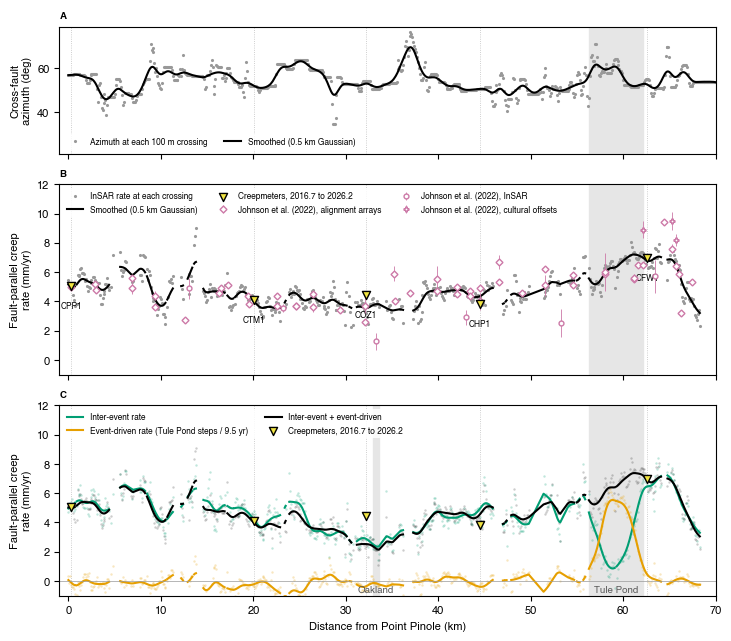

In [15]:
creep_rate_fp = pd.read_csv(os.path.join(paths_out["03_creep_timeseries"], "creep_rate_fp.csv"))
creep_rate_fp["km"] = to_km(creep_rate_fp["lat"].values)
flagged = creep_rate_fp["landslide_flag"].values.astype(bool)
trace_az = pd.read_csv(common_paths["fault_profiles"])
trace_az["km"] = to_km(trace_az["ft_lat"].values)
trace_az["az_smooth"] = gaussian_smooth_km(trace_az["profile_az"].values, trace_az["km"].values, rate_smooth_km)
budget_smooth = {name: gaussian_smooth_km(slip_budget[name].values, slip_budget["km"].values, rate_smooth_km)
                 for name in ("secular", "event_rate", "total")}
johnson = pd.read_csv(common_paths["creep_rates_Johnson22"])
johnson = johnson[johnson["Fault"].str.contains("Hayward") & (johnson["Type"] == "Int")].copy()
johnson["km"] = to_km(johnson["Latitude"].values)
johnson["sig"] = pd.to_numeric(johnson["sig (mm/yr)"], errors="coerce")
johnson = johnson[(johnson.km >= km_lim[0]) & (johnson.km <= km_lim[1])]
green = "#009E73"                                # Okabe-Ito bluish green: inter-event rate
orange = "#E69F00"                               # Okabe-Ito orange: event-driven
gold = "#F0E442"                                 # Okabe-Ito yellow: creepmeters
purple = "#CC79A7"                               # Okabe-Ito reddish purple: Johnson et al. (2022)
line_width = 1.5
cm_km = [v[0] for v in cm_rates.values()]
cm_rate = [v[1] for v in cm_rates.values()]

fig, axes = plt.subplots(3, 1, figsize=(7.2, 6.3), sharex=True, height_ratios=[1, 1.5, 1.5], constrained_layout=True)
for ax in axes:
    ax.axvspan(len_lo, len_hi, color="0.9", zorder=0)
    for km_cm in cm_km:
        ax.axvline(km_cm, color="0.75", lw=0.6, ls=":", zorder=0)

# A) trace azimuth
ax = axes[0]
ax.plot(trace_az.km, trace_az.profile_az, ".", color="0.6", ms=2.5, label="Azimuth at each 100 m crossing")
ax.plot(trace_az.km, trace_az.az_smooth, "-", color="k", lw=line_width, label=f"Smoothed ({rate_smooth_km:g} km Gaussian)")
ax.set_ylabel("Cross-fault\nazimuth (deg)")
ax.legend(fontsize=6, loc="lower left", ncol=2)
utils.panel_title(ax, "A")

# B) creep rate per crossing, with the independent rates
ax = axes[1]
ax.plot(creep_rate_fp.km[~flagged], creep_rate_fp.fp_creep_rate_raw[~flagged], ".", color="0.6", ms=2.5, label="InSAR rate at each crossing")
ax.plot(creep_rate_fp.km, creep_rate_fp.fp_creep_rate_smooth, "-", color="k", lw=line_width, label=f"Smoothed ({rate_smooth_km:g} km Gaussian)")
for inst, marker, label in (("AA", "D", "alignment arrays"), ("SAR", "o", "InSAR"), ("Cult", "P", "cultural offsets")):
    rows = johnson[johnson["Inst"] == inst]
    if len(rows):
        ax.errorbar(rows.km, rows["Creep rate (mm/yr)"], yerr=rows.sig, fmt=marker, ms=3.5, mfc="white", mec=purple,
                    ecolor=purple, elinewidth=0.6, capsize=0, zorder=4, label=f"Johnson et al. (2022), {label}")
ax.scatter(cm_km, cm_rate, marker="v", s=34, facecolor=gold, edgecolor="k", zorder=6, label=f"Creepmeters, {t0:.1f} to {t1:.1f}")
for code, (km_cm, rate_cm) in cm_rates.items():
    ax.annotate(code, (km_cm, rate_cm), xytext=(0, -11), textcoords="offset points", ha="center", va="top", fontsize=6)
ax.set_ylim(-1, 12)
ax.set_ylabel("Fault-parallel creep\nrate (mm/yr)")
ax.legend(fontsize=6, loc="upper left", ncol=3)
utils.panel_title(ax, "B")

# C) slip budget
ax = axes[2]
ax.axvspan(coz1_lo, coz1_hi, color="0.9", zorder=0)
for name, (span_lo, span_hi) in (("Tule Pond", (len_lo, len_hi)), ("Oakland", (coz1_lo, coz1_hi))):
    ax.text(0.5 * (span_lo + span_hi), -0.75, name, ha="center", fontsize=7, color="0.35")
ax.scatter(slip_budget.km, slip_budget.secular, s=3, color=green, alpha=0.25, lw=0)
ax.scatter(slip_budget.km, slip_budget.event_rate, s=3, color=orange, alpha=0.25, lw=0)
ax.scatter(slip_budget.km, slip_budget.total, s=3, color="k", alpha=0.2, lw=0)
ax.plot(slip_budget.km, budget_smooth["secular"], color=green, lw=line_width, label="Inter-event rate")
ax.plot(slip_budget.km, budget_smooth["event_rate"], color=orange, lw=line_width, label=f"Event-driven rate (Tule Pond steps / {span:.1f} yr)")
ax.plot(slip_budget.km, budget_smooth["total"], color="k", lw=line_width, label="Inter-event + event-driven")
ax.scatter(cm_km, cm_rate, marker="v", s=34, facecolor=gold, edgecolor="k", zorder=6, label=f"Creepmeters, {t0:.1f} to {t1:.1f}")
ax.set_ylim(-1, 12)
ax.axhline(0, color="0.6", lw=0.5)
ax.set_ylabel("Fault-parallel creep\nrate (mm/yr)")
ax.legend(fontsize=6, loc="upper left", ncol=2)
utils.panel_title(ax, "C")
ax.set_xlim(*km_lim)
ax.set_xlabel("Distance from Point Pinole (km)")
f_budget = os.path.join(fig_dir, f"figS_creep_rate_along_fault_{params}.png")
fig.savefig(f_budget, dpi=300)
fig.savefig(f_budget.replace(".png", ".pdf"))
print("Saved figure to:", f_budget)
plt.show()

## 16. Register

The stats file `04_events_stats.txt` (the numbers above, in words) and the registry rows `04_*` that the paper
quotes.

In [16]:
stats_lines = ["04 EVENT DETECTION",
               f"stream {params}; stack +/-{stack_half_km:g} km along the trace of the section centre; matched filter {win_n} epochs, "
               f"{k_sigma:g} sigma; joint model linear + annual + steps; {nboot} block bootstraps (~{block_years:g} yr blocks)", ""]
for key, sol in solutions.items():
    stats_lines.append(f"[{segments[key]['label']}] stack n = {sol['n']}, rate {sol['coef'][1]:.2f} mm/yr, "
                       f"annual {np.hypot(sol['coef'][2], sol['coef'][3]):.2f} mm, rms {np.sqrt(sol['rss'] / len(sol['dates'])):.2f} mm")
    for event_fit in sol["fits"]:
        stats_lines.append(f"   onset window [{event_fit['onset_lo']:.4f}, {event_fit['onset_hi']:.4f}] "
                           f"amp {event_fit['amplitude_mm']:.2f} [{event_fit['amp_lo']:.2f}, {event_fit['amp_hi']:.2f}] mm")
stats_lines += ["", f"COZ1 control events ({len(coz1_events)}; label = onset day; the two large known ones at "
                f"{', '.join(f'{known_yr:g}' for known_yr in coz1_large_events_yr)} asserted among them):"]
for event in coz1_events.itertuples():
    stats_lines.append(f"   {event.onset_day}: window [{event.onset_lo:.4f}, {event.onset_hi:.4f}] ({event.onset_window_days:.0f} d), "
                       f"InSAR {event.amplitude_mm:.2f} [{event.amp_lo:.2f}, {event.amp_hi:.2f}] mm, statistic {event.detect_stat_mm:.2f} mm "
                       f"({event.detect_stat_mm / event.detect_sigma_mm:.2f} sigma), creepmeter step {event.creepmeter_step_mm:.2f} mm")
stats_lines += ["", "event-driven fraction (crossings within the stack half-width of the section centre):"]
for key, stats in frac_stats.items():
    stats_lines.append(f"   {segments[key]['label']}: n {stats['n']}, summed slip median {stats['sum_median']:.1f} mm, "
                       f"fraction median {stats['median']:.0f}%, 5-95% {stats['p5']:.0f} to {stats['p95']:.0f}%")
stats_lines += ["", f"window {w_lo:.1f} to {w_hi:.1f} km (re-centred on the cumulative-slip peak at {peak_km:.1f} km); "
                f"median of the per-crossing inter-event rates in the window {inter_event_rate_median:.2f} mm/yr",
                f"cumulative event slip peak {peak_cum:.1f} mm; flank threshold {length_threshold:.2f} mm (median {flank_median:.2f} + 3 x {flank_sigma:.2f})",
                f"length hosting the events: {len_lo:.1f} to {len_hi:.1f} km ({len_hi - len_lo:.1f} km, {len_n} crossings)",
                "10-90% edge widths of the cumulative event slip: " + "; ".join(
                    f"{end} {width:.2f} km (90% at {km_90:.2f}, 10% at {km_10:.2f} km)" for end, (km_90, km_10, width) in edge_widths.items()),
                f"fraction peak {peak_frac:.1f}%"]
for band_frac, (lo_km, hi_km, n_band) in bands.items():
    result = band_results[band_frac]
    stats_lines.append(f"band {100 * band_frac:.0f}%: {lo_km:.1f} to {hi_km:.1f} km ({hi_km - lo_km:.1f} km, {n_band} crossings); "
                       f"secular {result['secular']:.2f} mm/yr, annual {result['annual']:.2f} mm, rms {result['rms']:.2f} mm")
    step_texts = []
    for step_epoch, step, ci_lo, ci_hi in zip(step_epochs_tulepond, result["steps"], result["ci_lo"], result["ci_hi"]):
        step_texts.append(f"{step_epoch:.3f} {step:.2f} [{ci_lo:.2f}, {ci_hi:.2f}]")
    stats_lines.append("   steps: " + ", ".join(step_texts) + f"; sum {np.sum(result['steps']):.1f}, mean {np.mean(result['steps']):.1f} mm")
stats_lines += ["", f"alignment arrays along the Tule Pond section ({len_lo - 1:.1f}-{len_hi + 1:.1f} km), refit over the InSAR window "
                f"{aa_window_text} (mm/yr, 1 sigma): " + ", ".join(
                    f"{row.code} {row.rate_window:.2f} +/- {row.rate_window_se:.2f} (n {row.n_window})" for row in in_section.itertuples())]
stats_lines += ["", "slip budget (mm/yr; arrays within 1 km of the block, refit over the InSAR window / whole record):"]
for name, block in budget.items():
    stats_lines.append(f"   {block['name']}: {block['lo']:.1f} to {block['hi']:.1f} km n {block['n']}: secular {block['secular']:.2f}, "
                       f"event {block['event_rate']:.2f}, total {block['total']:.2f} ({block['frac_pct']:.0f}%), arrays window "
                       f"{block['aa_window_mean']:.2f} (n {block['aa_window_n']}), long-term {block['aa_longterm_mean']:.2f} (n {block['aa_n']})")
stats_lines += ["", f"seismicity (GrowClust) within {seis_max_dist_km:g} km, window {w_lo:.0f}-{w_hi:.0f} km: {n_seis_win} earthquakes, "
                f"{n_cre_win} repeaters, {n_cre_band} repeaters in the {100 * band_main:.0f}% band",
                *seis_count_lines, "catalogue spans of the events kept: " + "; ".join(catalogue_spans),
                f"hovmoller colour scale {vmin:.0f} to {vmax:.0f} mm"]
sidecar = REG.sidecar("04_events", stats_lines)

REG.register("04_n_events", len(tulepond_events), "count", 0, where="P3, abstract", cell="detect", sidecar=sidecar)
REG.register("04_detect_sigma_mm", float(tulepond_events.detect_sigma_mm[0]), "mm", 3, where="M5", cell="detect", sidecar=sidecar)
REG.register("04_threshold_mm", k_sigma * float(tulepond_events.detect_sigma_mm[0]), "mm", 2, where="M5", cell="detect", sidecar=sidecar)
REG.register("04_stack_n_crossings", solutions["TULEPOND"]["n"], "count", 0, where="M5", cell="detect", sidecar=sidecar)
labels = []
for step_epoch in step_epochs_tulepond:
    labels.append(f"{int(step_epoch)}")
for label, (_, event) in zip(labels, tulepond_events.iterrows()):
    REG.register(f"04_onset_lo_{label}", event.onset_lo, "decyear", 4, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_onset_hi_{label}", event.onset_hi, "decyear", 4, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_onset_window_days_{label}", event.onset_window_days, "d", 0, where="P3", cell="joint-fit", sidecar=sidecar)
    REG.register(f"04_stack_amp_{label}_mm", event.amplitude_mm, "mm", 2, where="M5", cell="joint-fit", sidecar=sidecar)
for band_frac, (lo_km, hi_km, n_band) in bands.items():
    result = band_results[band_frac]
    tag = f"band{int(band_frac * 100)}"
    REG.register(f"04_{tag}_lo_km", lo_km, "km", 1, where="Fig1 caption, P3", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_hi_km", hi_km, "km", 1, where="Fig1 caption, P3", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_width_km", hi_km - lo_km, "km", 1, where="P3", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_n_crossings", n_band, "count", 0, where="Fig1 caption", cell="band", sidecar=sidecar)
    REG.register(f"04_{tag}_inter_event_mm_yr", result["secular"], "mm/yr", 2, where="P4, Fig1 caption", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_annual_mm", result["annual"], "mm", 2, where="Fig1 caption", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_sum_mm", float(np.sum(result["steps"])), "mm", 1, where="Fig1 caption", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_mean_mm", float(np.mean(result["steps"])), "mm", 1, where="P3", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_min_mm", float(np.min(result["steps"])), "mm", 1, where="P3", cell="band-stack", sidecar=sidecar)
    REG.register(f"04_{tag}_steps_max_mm", float(np.max(result["steps"])), "mm", 1, where="P3", cell="band-stack", sidecar=sidecar)
    for label, step, ci_lo, ci_hi in zip(labels, result["steps"], result["ci_lo"], result["ci_hi"]):
        REG.register(f"04_{tag}_step_{label}_mm", step, "mm", 2, where="P3", cell="band-stack", sidecar=sidecar)
        REG.register(f"04_{tag}_step_{label}_ci_lo", ci_lo, "mm", 2, where="P3", cell="band-stack", sidecar=sidecar)
        REG.register(f"04_{tag}_step_{label}_ci_hi", ci_hi, "mm", 2, where="P3", cell="band-stack", sidecar=sidecar)
REG.register("04_creep_length_km", len_hi - len_lo, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_lo_km", len_lo, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_hi_km", len_hi, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_n_crossings", len_n, "count", 0, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_creep_length_threshold_mm", length_threshold, "mm", 2, where="M6", cell="section-length", sidecar=sidecar)
for end, (km_90, km_10, width) in edge_widths.items():
    REG.register(f"04_edge_{end}_10_90_km", width, "km", 1, where="P3", cell="section-length", sidecar=sidecar)
REG.register("04_fraction_peak_pct", peak_frac, "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_fraction_median_pct", frac_stats["TULEPOND"]["median"], "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_fraction_p5_pct", frac_stats["TULEPOND"]["p5"], "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_fraction_p95_pct", frac_stats["TULEPOND"]["p95"], "pct", 0, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_event_slip_sum_median_mm", frac_stats["TULEPOND"]["sum_median"], "mm", 1, where="P3", cell="fraction", sidecar=sidecar)
REG.register("04_hovmoller_bg_rate_mm_yr", inter_event_rate_median, "mm/yr", 1, where="Fig1 caption", cell="hovmoller", sidecar=sidecar)
REG.register("04_hovmoller_vmax_mm", vmax, "mm", 0, where="Fig1 caption", cell="hovmoller", sidecar=sidecar)
for name, block in budget.items():
    for quantity in ("secular", "event_rate", "total"):
        REG.register(f"04_budget_{name}_{quantity.replace('secular', 'inter_event')}_mm_yr", block[quantity], "mm/yr", 2, where="P4, Fig1c", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{name}_event_pct", block["frac_pct"], "pct", 0, where="P4", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{name}_aa_window_mm_yr", block["aa_window_mean"], "mm/yr", 2, where="P4, Fig1c", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{name}_aa_longterm_mm_yr", block["aa_longterm_mean"], "mm/yr", 2, where="P4, Fig1c", cell="budget", sidecar=sidecar)
    REG.register(f"04_budget_{name}_aa_n", block["aa_n"], "count", 0, where="Fig1 caption", cell="budget", sidecar=sidecar)
REG.register("04_record_span_yr", span, "yr", 2, where="Fig1 caption", cell="budget", sidecar=sidecar)
# the arrays along the section, each refit over the InSAR window (its first and last day registered with them)
REG.register("04_aa_window_first_day", str(utils.decimal_year_to_day(t0).date()), "date", 0, where="P4 (array refit = InSAR window)", cell="budget", sidecar=sidecar)
REG.register("04_aa_window_last_day", str(utils.decimal_year_to_day(t1).date()), "date", 0, where="P4 (array refit = InSAR window)", cell="budget", sidecar=sidecar)
for array_row in in_section.itertuples():
    REG.register(f"04_aa_{array_row.code.lower()}_window_rate_mm_yr", array_row.rate_window, "mm/yr", 2, where="P4 (refit over the InSAR window)", cell="budget", sidecar=sidecar)
    REG.register(f"04_aa_{array_row.code.lower()}_window_rate_se_mm_yr", array_row.rate_window_se, "mm/yr", 2, where="P4 (refit over the InSAR window)", cell="budget", sidecar=sidecar)
    REG.register(f"04_aa_{array_row.code.lower()}_window_n_surveys", array_row.n_window, "count", 0, where="P4 (refit over the InSAR window)", cell="budget", sidecar=sidecar)
REG.register("04_n_seis_window", n_seis_win, "count", 0, where="Fig1 caption", cell="catalogues", sidecar=sidecar)
REG.register("04_n_cre_window", n_cre_win, "count", 0, where="Fig1 caption", cell="catalogues", sidecar=sidecar)
REG.register("04_n_cre_band", n_cre_band, "count", 0, where="P3", cell="catalogues", sidecar=sidecar)
# the discussion's counts: within seis_max_dist_km of the trace over the InSAR period, in the section and in the band
for span_name in seis_count_spans:
    REG.register(f"04_n_seis_{span_name}", seis_counts[(span_name, "seis_all")], "count", 0, where="Discussion (seismicity)", cell="catalogues", sidecar=sidecar)
    REG.register(f"04_n_seis_reloc_{span_name}", seis_counts[(span_name, "seis_reloc")], "count", 0, where="Discussion (seismicity)", cell="catalogues", sidecar=sidecar)
    REG.register(f"04_n_cre_{span_name}", seis_counts[(span_name, "cre_all")], "count", 0, where="Discussion (seismicity)", cell="catalogues", sidecar=sidecar)
    REG.register(f"04_n_cre_taira_{span_name}", seis_counts[(span_name, "cre_taira")], "count", 0, where="Discussion (seismicity)", cell="catalogues", sidecar=sidecar)
    REG.register(f"04_n_cre_wald_{span_name}", seis_counts[(span_name, "cre_wald")], "count", 0, where="Discussion (seismicity)", cell="catalogues", sidecar=sidecar)
# the COZ1 control events (section 5: the two large known ones among them), labelled by onset day (2019_01_09, ...)
# because two COZ1 events fall in 2022
coz1_detect_sigma_mm = float(coz1_events.detect_sigma_mm.iloc[0])      # one statistic sigma per stack (the same on every row)
assert (coz1_events.detect_sigma_mm == coz1_events.detect_sigma_mm.iloc[0]).all(), "the COZ1 rows carry different detection sigmas"
REG.register("04_control_coz1_n_events", len(coz1_events), "count", 0, where="M5 (control)", cell="detect", sidecar=sidecar)
REG.register("04_control_coz1_detect_sigma_mm", coz1_detect_sigma_mm, "mm", 3, where="M5 (control)", cell="detect", sidecar=sidecar)
REG.register("04_control_coz1_threshold_mm", k_sigma * coz1_detect_sigma_mm, "mm", 2, where="M5 (control)", cell="detect", sidecar=sidecar)
for event in coz1_events.itertuples():
    label = event.onset_day.replace("-", "_")                          # the onset day (unique, asserted in section 5)
    REG.register(f"04_control_coz1_onset_{label}", event.onset_lo, "decyear", 3, where="M5 (control)", cell="detect", sidecar=sidecar)   # the step epoch = onset_lo
    REG.register(f"04_control_coz1_onset_hi_{label}", event.onset_hi, "decyear", 4, where="M5 (control)", cell="detect", sidecar=sidecar)
    REG.register(f"04_control_coz1_amp_{label}_mm", event.amplitude_mm, "mm", 2, where="M5 (control)", cell="detect", sidecar=sidecar)
    REG.register(f"04_control_coz1_creepmeter_{label}_mm", event.creepmeter_step_mm, "mm", 2, where="M5 (control)", cell="detect", sidecar=sidecar)
REG.render()

Saved stats to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/04_event_detection/04_events_stats.txt


  registered 04_n_events = 5 count  -> P3, abstract
  registered 04_detect_sigma_mm = 0.824 mm  -> M5


  registered 04_threshold_mm = 2.47 mm  -> M5


  registered 04_stack_n_crossings = 39 count  -> M5
  registered 04_onset_lo_2017 = 2017.0986 decyear  -> P3
  registered 04_onset_hi_2017 = 2017.1315 decyear  -> P3


  registered 04_onset_window_days_2017 = 12 d  -> P3


  registered 04_stack_amp_2017_mm = 10.03 mm  -> M5
  registered 04_onset_lo_2019 = 2019.1863 decyear  -> P3


... (52 outputs left out)

  registered 04_control_coz1_creepmeter_2019_01_09_mm = 4.41 mm  -> M5 (control)
  registered 04_control_coz1_onset_2022_02_16 = 2022.126 decyear  -> M5 (control)
  registered 04_control_coz1_onset_hi_2022_02_16 = 2022.1589 decyear  -> M5 (control)
  registered 04_control_coz1_amp_2022_02_16_mm = 3.93 mm  -> M5 (control)


  registered 04_control_coz1_creepmeter_2022_02_16_mm = 6.68 mm  -> M5 (control)
  registered 04_control_coz1_onset_2022_10_02 = 2022.751 decyear  -> M5 (control)
  registered 04_control_coz1_onset_hi_2022_10_02 = 2022.8164 decyear  -> M5 (control)


  registered 04_control_coz1_amp_2022_10_02_mm = 1.39 mm  -> M5 (control)
  registered 04_control_coz1_creepmeter_2022_10_02_mm = 1.47 mm  -> M5 (control)
  01_prep_inputs: its latest run registered no numbers; its numbers are left out
Wrote the numbers to: /Users/dlindsay/work/proj_TulePond_DISP/outputs/paper_numbers.md


'/Users/dlindsay/work/proj_TulePond_DISP/outputs/paper_numbers.md'